<a href="https://colab.research.google.com/github/zbnerd/ROKEY_prac/blob/main/lee_seungjun/261110_study_lsj.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 이미지·라벨 매칭 검사

In [5]:

from pathlib import Path
from collections import Counter
from pprint import pprint
import unicodedata
import json
import pandas as pd

# ==============================
# 0. 구글 드라이브 마운트
# ==============================
from google.colab import drive
import os

if not os.path.exists("/content/drive"):
    drive.mount("/content/drive")

# ==============================
# 1. 데이터 경로
# ==============================

BASE = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "AI개론/261110스터디"
)

IMAGE_ROOT = BASE / "Images"
LABEL_ROOT = BASE / "labels"

assert IMAGE_ROOT.is_dir(), IMAGE_ROOT
assert LABEL_ROOT.is_dir(), LABEL_ROOT

# ==============================
# 2. 클래스 설정
# ==============================

CLASS_CONFIG = {
    0: ("styrofoam", "05", "001"),
    1: ("vinyl", "06", "001"),
    2: ("brown_glass", "07", "001"),
    3: ("green_glass", "07", "002"),
    4: ("clear_glass", "07", "003"),
}

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

# ==============================
# 3. 폴더 자동 검색
# ==============================

def find_class_dir(root, prefix, category, detail):
    matches = []

    for folder in root.iterdir():
        if not folder.is_dir():
            continue

        name = unicodedata.normalize("NFC", folder.name)

        # VS_1.영상추출_05.스티로폼_001.스티로폼
        # VL_1.영상추출_05.스티로폼_001.스티로폼

        if not name.startswith(f"{prefix}_1.영상추출_"):
            continue

        if f"_{category}." not in name:
            continue

        if f"_{detail}." not in name:
            continue

        matches.append(folder)

    if len(matches) != 1:
        print(f"\n검색 실패: {category}/{detail}")
        print("검색 위치:", root)
        print("실제 하위 폴더:")
        for folder in root.iterdir():
            print(repr(folder.name))

        raise ValueError(
            f"일치하는 폴더가 정확히 1개여야 합니다: {matches}"
        )

    return matches[0]


# ==============================
# 4. 이미지 / JSON 매칭
# ==============================

records = []
samples = []
CLASS_SOURCES = {}

for class_id, (name, category, detail) in CLASS_CONFIG.items():

    image_dir = find_class_dir(
        IMAGE_ROOT, "VS", category, detail
    )

    label_dir = find_class_dir(
        LABEL_ROOT, "VL", category, detail
    )

    CLASS_SOURCES[class_id] = {
        "name": name,
        "images": image_dir,
        "labels": label_dir
    }

    image_files = sorted(
        p for p in image_dir.rglob("*")
        if p.suffix.lower() in IMAGE_EXTENSIONS
    )

    label_files = sorted(
        label_dir.rglob("*.json")
    )

    image_stems = Counter(p.stem for p in image_files)
    label_stems = Counter(p.stem for p in label_files)

    matched = sum(
        min(image_stems[k], label_stems[k])
        for k in image_stems.keys() & label_stems.keys()
    )

    records.append({
        "ID": class_id,
        "Class": name,
        "Images": len(image_files),
        "JSON": len(label_files),
        "Matched": matched,
        "Missing Labels": sum(
            (image_stems - label_stems).values()
        ),
        "Missing Images": sum(
            (label_stems - image_stems).values()
        )
    })

    if label_files:
        with open(
            label_files[0], encoding="utf-8-sig"
        ) as f:
            data = json.load(f)

        samples.append({
            "class": name,
            "image_example": (
                image_files[0].name if image_files else None
            ),
            "json_example": label_files[0].name,
            "IMAGE_INFO": data.get("IMAGE_INFO", {}),
            "ANNOTATION_INFO": (
                data.get("ANNOTATION_INFO", [])[:1]
            )
        })

# ==============================
# 5. 결과
# ==============================

df_classes = pd.DataFrame(records)
display(df_classes)

print("\n전체 이미지:", df_classes["Images"].sum())
print("전체 JSON:", df_classes["JSON"].sum())
print("파일명 기준 매칭:", df_classes["Matched"].sum())

print("\n===== JSON 구조 예시 =====")
for sample in samples:
    print("\nCLASS:", sample["class"])
    print("IMAGE:", sample["image_example"])
    print("JSON:", sample["json_example"])
    pprint(sample["IMAGE_INFO"])
    pprint(sample["ANNOTATION_INFO"])

print("\n폴더 매핑 완료!")

Mounted at /content/drive


,ID,Class,Images,JSON,Matched,Missing Labels,Missing Images
0,0,styrofoam,1504,1504,1504,0,0
1,1,vinyl,902,902,902,0,0
2,2,brown_glass,1810,1810,1810,0,0
3,3,green_glass,904,904,904,0,0
4,4,clear_glass,907,907,907,0,0



전체 이미지: 6027
전체 JSON: 6027
파일명 기준 매칭: 6027

===== JSON 구조 예시 =====

CLASS: styrofoam
IMAGE: 1002917@0_05001_220907_P1_T3__2226.jpg
JSON: 1002917@0_05001_220907_P1_T3__2226.json
{'DATE': '2022-10-24 16:35:24',
 'DAY/NIGHT': '주간',
 'Direction': '0',
 'EXPOSURE_TIME': '1/400',
 'FILE_NAME': '1002917@0_05001_220907_P1_T3__2226.jpg',
 'FOCUS_DISTANCE': '5.6',
 'HEIGHT': '100',
 'IMAGE_HEIGHT': 1080,
 'IMAGE_PHOTOGRAPHER': '이지은',
 'IMAGE_SIZE': '672.4 KB',
 'IMAGE_WIDTH': 1920,
 'PLACE': '용인시재활용센터',
 'REGION_NAME': None,
 'RESOLUTION': '1920 x 1080',
 'SENSITIVITY_ISO': '4000',
 'WEATHER': '맑음'}
[{'CLASS': '스티로폼',
  'COVER': '없음',
  'DAMAGE': '파손',
  'DETAILS': '스티로폼',
  'DIRTINESS': '이물질(외부)',
  'ID': '1',
  'POINTS': [[739.2633660567823,
              148.38348264984225,
              229.7379815772871,
              266.5442725552052]],
  'SHAPE': '식품용기형',
  'SHAPE_TYPE': 'BOX',
  'TRANSPARENCY': '불투명'}]

CLASS: vinyl
IMAGE: 1001324@0_06001_220906_P1_T3__2083.jpg
JSON: 1001324@0_06001_22

# 어노테이션과 촬영 그룹 분석

In [6]:

from collections import Counter, defaultdict
from pathlib import Path
from tqdm.auto import tqdm
import pandas as pd
import json
import re

shape_counts = Counter()
object_counts = Counter()
groups = defaultdict(Counter)
invalid_labels = Counter()

def get_capture_group(filename):
    """
    예: ..._07001_220919_P1_T3__2352.jpg
    → 220919_P1_T3
    """
    match = re.search(
        r"_(\d{6})_(P\d+)_(T\d+)__\d+$",
        Path(filename).stem
    )

    if match:
        return "_".join(match.groups())

    return None

for class_id, source in CLASS_SOURCES.items():
    class_name = source["name"]
    json_paths = sorted(source["labels"].rglob("*.json"))

    for path in tqdm(
        json_paths,
        desc=class_name,
        unit="json"
    ):
        with open(path, encoding="utf-8-sig") as f:
            data = json.load(f)

        image_info = data.get("IMAGE_INFO", {})
        filename = image_info.get("FILE_NAME", "")

        group = get_capture_group(filename)

        if group is None:
            invalid_labels[class_name] += 1
        else:
            groups[class_name][group] += 1

        for obj in data.get("ANNOTATION_INFO", []):
            shape_counts[
                (class_name, obj.get("SHAPE_TYPE"))
            ] += 1

            object_counts[
                (
                    obj.get("CLASS"),
                    obj.get("DETAILS")
                )
            ] += 1

print("\n===== SHAPE_TYPE 분포 =====")

display(pd.DataFrame([
    {
        "Class": cls,
        "Shape": shape,
        "Objects": count
    }
    for (cls, shape), count in shape_counts.items()
]))

print("\n===== 실제 객체 클래스 분포 =====")

display(pd.DataFrame([
    {
        "CLASS": cls,
        "DETAILS": details,
        "Objects": count
    }
    for (cls, details), count in object_counts.items()
]).sort_values("Objects", ascending=False))

print("\n===== 촬영 그룹별 이미지 수 =====")

for cls, counter in groups.items():
    print(f"\n{cls}: {len(counter)}개 그룹")
    print("상위 그룹:", counter.most_common(10))

print("\n그룹 추출 실패:", dict(invalid_labels))


styrofoam:   0%|          | 0/1504 [00:00<?, ?json/s]

vinyl:   0%|          | 0/902 [00:00<?, ?json/s]

brown_glass:   0%|          | 0/1810 [00:00<?, ?json/s]

green_glass:   0%|          | 0/904 [00:00<?, ?json/s]

clear_glass:   0%|          | 0/907 [00:00<?, ?json/s]


===== SHAPE_TYPE 분포 =====


,Class,Shape,Objects
0,styrofoam,BOX,1984
1,styrofoam,POLYGON,1471
2,vinyl,BOX,1569
3,vinyl,POLYGON,1317
4,brown_glass,POLYGON,714
5,brown_glass,BOX,3882
6,green_glass,BOX,789
7,green_glass,POLYGON,437
8,clear_glass,POLYGON,526
9,clear_glass,BOX,1066



===== 실제 객체 클래스 분포 =====


,CLASS,DETAILS,Objects
2,유리병,갈색,4596
0,스티로폼,스티로폼,3455
1,비닐,비닐,2886
4,유리병,투명,1592
3,유리병,녹색,1226



===== 촬영 그룹별 이미지 수 =====

styrofoam: 6개 그룹
상위 그룹: [('221020_P1_T3', 644), ('221006_P1_T3', 452), ('220907_P1_T3', 317), ('221026_P1_T3', 61), ('220906_P1_T3', 27), ('220913_P1_T3', 3)]

vinyl: 7개 그룹
상위 그룹: [('221006_P1_T3', 699), ('220907_P1_T3', 94), ('220906_P1_T3', 81), ('221026_P1_T3', 25), ('220829_P1_T3', 1), ('220913_P1_T3', 1), ('220822_P1_T3', 1)]

brown_glass: 4개 그룹
상위 그룹: [('220822_P1_T3', 1580), ('220919_P1_T3', 190), ('221026_P1_T3', 38), ('220907_P1_T3', 2)]

green_glass: 3개 그룹
상위 그룹: [('220919_P1_T3', 517), ('220822_P1_T3', 378), ('221026_P1_T3', 9)]

clear_glass: 3개 그룹
상위 그룹: [('220919_P1_T3', 858), ('220822_P1_T3', 43), ('221026_P1_T3', 6)]

그룹 추출 실패: {}


In [7]:

from collections import Counter
import pandas as pd
import re

records = []

pattern = re.compile(
    r"^(?P<item_id>[^_]+)_"
    r"(?P<category>\d{5})_"
    r"(?P<date>\d{6})_"
    r"(?P<position>P\d+)_"
    r"(?P<track>T\d+)__"
    r"(?P<frame>\d+)$"
)

for class_id, source in CLASS_SOURCES.items():
    for path in source["labels"].rglob("*.json"):
        match = pattern.match(path.stem)

        if match is None:
            continue

        record = match.groupdict()

        records.append({
            "class_id": class_id,
            "class_name": source["name"],
            "filename": path.stem,
            "item_id": record["item_id"],
            "date": record["date"],
            "position": record["position"],
            "track": record["track"],
            "frame": int(record["frame"])
        })

df_frames = pd.DataFrame(records)

print("파싱 성공:", len(df_frames))

summary = (
    df_frames
    .groupby([
        "class_name", "date",
        "position", "track"
    ])
    .agg(
        images=("filename", "count"),
        unique_ids=("item_id", "nunique"),
        unique_frames=("frame", "nunique"),
        first_frame=("frame", "min"),
        last_frame=("frame", "max")
    )
    .reset_index()
    .sort_values(
        ["class_name", "images"],
        ascending=[True, False]
    )
)

display(summary)


파싱 성공: 6027


,class_name,date,position,track,images,unique_ids,unique_frames,first_frame,last_frame
0,brown_glass,220822,P1,T3,1580,790,703,2,2393
2,brown_glass,220919,P1,T3,190,95,94,5,2959
3,brown_glass,221026,P1,T3,38,19,19,408,5018
1,brown_glass,220907,P1,T3,2,1,1,1735,1735
5,clear_glass,220919,P1,T3,858,858,722,0,3147
4,clear_glass,220822,P1,T3,43,43,42,72,2296
6,clear_glass,221026,P1,T3,6,6,6,461,1686
8,green_glass,220919,P1,T3,517,517,487,1,3584
7,green_glass,220822,P1,T3,378,378,357,1,2383
9,green_glass,221026,P1,T3,9,9,9,148,3107


# 그룹 기반 Train / Val / Test 분할

In [8]:

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit

SEED = 42
BLOCK_SIZE = 300

df_split = df_frames.reset_index(drop=True).copy()

# 1. 프레임 번호를 구간으로 묶기
df_split["frame_block"] = (
    df_split["frame"].astype(int) // BLOCK_SIZE
)

# 클래스가 달라도 같은 날짜 코드·프레임 구간이면 함께 묶기
df_split["block_key"] = (
    df_split["date"].astype(str) + "|" +
    df_split["position"].astype(str) + "|" +
    df_split["track"].astype(str) + "|" +
    df_split["frame_block"].astype(str)
)

# 동일 item_id의 중복 이미지도 함께 묶기
df_split["item_key"] = (
    df_split["class_name"].astype(str) + "|" +
    df_split["date"].astype(str) + "|" +
    df_split["item_id"].astype(str)
)

# 2. 두 그룹 조건을 모두 만족시키는 연결 그룹 생성
parent = list(range(len(df_split)))

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

first_block = {}
first_item = {}

for i, row in df_split.iterrows():
    for key, registry in [
        (row["block_key"], first_block),
        (row["item_key"], first_item)
    ]:
        if key in registry:
            union(i, registry[key])
        else:
            registry[key] = i

df_split["group_id"] = [
    find(i) for i in range(len(df_split))
]

print("이미지:", len(df_split))
print("독립 후보 그룹:", df_split["group_id"].nunique())

# 3. 그룹 단위로 분할
# 목표 비율: train 70%, val 15%, test 15%
target = np.array([0.70, 0.15, 0.15])
split_names = ["train", "val", "test"]

best_score = float("inf")
best_labels = None

for seed in range(SEED, SEED + 300):
    outer = GroupShuffleSplit(
        n_splits=1,
        test_size=0.15,
        random_state=seed
    )

    trainval_idx, test_idx = next(
        outer.split(df_split, groups=df_split["group_id"])
    )

    remaining = df_split.iloc[trainval_idx]

    inner = GroupShuffleSplit(
        n_splits=1,
        test_size=0.15 / 0.85,
        random_state=seed + 1000
    )

    tr_pos, val_pos = next(
        inner.split(
            remaining,
            groups=remaining["group_id"]
        )
    )

    train_idx = trainval_idx[tr_pos]
    val_idx = trainval_idx[val_pos]

    assignments = np.empty(len(df_split), dtype=object)
    assignments[train_idx] = "train"
    assignments[val_idx] = "val"
    assignments[test_idx] = "test"

    counts = pd.crosstab(
        df_split["class_name"], assignments
    ).reindex(columns=split_names, fill_value=0)

    ratios = counts.div(counts.sum(axis=1), axis=0)

    # 클래스별 비율과 전체 비율을 함께 고려
    score = np.abs(
        ratios.to_numpy() - target
    ).sum()

    overall = np.array([
        np.sum(assignments == s) for s in split_names
    ]) / len(assignments)

    score += np.abs(overall - target).sum()

    # 특정 클래스가 아예 없는 분할은 강하게 불이익
    score += 100 * (counts.to_numpy() == 0).sum()

    if score < best_score:
        best_score = score
        best_labels = assignments.copy()

df_split["split"] = best_labels

# 4. 그룹 누수 검사
for i, a in enumerate(split_names):
    for b in split_names[i + 1:]:
        ga = set(df_split.loc[
            df_split["split"] == a, "group_id"
        ])
        gb = set(df_split.loc[
            df_split["split"] == b, "group_id"
        ])
        assert ga.isdisjoint(gb), f"그룹 중복: {a}/{b}"

summary = pd.crosstab(
    df_split["class_name"],
    df_split["split"]
).reindex(columns=split_names, fill_value=0)

display(summary)

print("\n전체 분할:")
print(df_split["split"].value_counts())

if (summary == 0).any().any():
    raise RuntimeError(
        "특정 분할에 없는 클래스가 있습니다. "
        "현재 그룹 구조로는 균형 잡힌 분할이 어렵습니다."
    )

print("\n그룹 중복 검사 통과")


이미지: 6027
독립 후보 그룹: 75


split,train,val,test
class_name,,,
brown_glass,1266,262,282
clear_glass,644,152,111
green_glass,582,158,164
styrofoam,1027,323,154
vinyl,569,133,200



전체 분할:
split
train    4088
val      1028
test      911
Name: count, dtype: int64

그룹 중복 검사 통과


# 클래스별 최대 400장 선택

In [12]:

from pathlib import Path
from collections import defaultdict
from tqdm.auto import tqdm
import pandas as pd

SEED = 42

MAX_PER_CLASS = {
    "train": 280,
    "val": 60,
    "test": 60
}

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

# ==========================================
# 1. 중복 행 제거
# ==========================================

conflicts = (
    df_split
    .groupby(["class_id", "filename"])["split"]
    .nunique()
)

assert (conflicts <= 1).all(), (
    "동일 파일이 서로 다른 분할에 포함되었습니다."
)

df_unique = df_split.drop_duplicates(
    subset=["class_id", "filename"]
).copy()

print("중복 제거 전:", len(df_split))
print("중복 제거 후:", len(df_unique))

# ==========================================
# 2. 클래스별 최대 400장 샘플링
# ==========================================

sampled_parts = []

classes = sorted(df_unique["class_name"].unique())

for class_name in tqdm(
    classes,
    desc="클래스별 샘플링",
    unit="class"
):
    for split, limit in MAX_PER_CLASS.items():

        subset = df_unique[
            (df_unique["class_name"] == class_name) &
            (df_unique["split"] == split)
        ]

        if len(subset) == 0:
            continue

        selected = subset.sample(
            n=min(len(subset), limit),
            random_state=SEED
        )

        sampled_parts.append(selected)

df_selected = pd.concat(
    sampled_parts,
    ignore_index=True
)

print("샘플링 완료:", len(df_selected))

# ==========================================
# 3. 빠른 파일 인덱스
# ==========================================

def fast_index(root, extensions, nested_name):
    """
    상위 폴더와 알려진 중복 하위 폴더만 검사.
    모든 파일의 SHA-256 계산은 하지 않음.
    """
    index = defaultdict(list)

    folders = [
        root,
        root / nested_name
    ]

    for folder in folders:
        if not folder.is_dir():
            continue

        for path in folder.iterdir():
            if path.is_file() and path.suffix.lower() in extensions:
                index[path.stem].append(path)

    return index


FILE_INDEX = {}

for class_id, source in tqdm(
    CLASS_SOURCES.items(),
    total=len(CLASS_SOURCES),
    desc="클래스별 파일 인덱싱",
    unit="class"
):
    images = fast_index(
        source["images"],
        IMAGE_EXTENSIONS,
        "validation_image"
    )

    labels = fast_index(
        source["labels"],
        {".json"},
        "validation_label"
    )

    FILE_INDEX[class_id] = {
        "images": images,
        "labels": labels
    }

# ==========================================
# 4. 파일 경로 연결
# ==========================================

def select_file(paths, root, stem):
    if not paths:
        raise FileNotFoundError(
            f"파일 없음: {root}/{stem}"
        )

    if len(paths) > 1:
        sizes = {p.stat().st_size for p in paths}

        if len(sizes) != 1:
            raise ValueError(
                f"중복 파일 크기가 다릅니다: {stem}"
            )

    # 상위 폴더 파일 우선
    return min(
        paths,
        key=lambda p: (
            len(p.relative_to(root).parts),
            str(p)
        )
    )


image_paths = []
label_paths = []

for row in tqdm(
    df_selected.itertuples(index=False),
    total=len(df_selected),
    desc="이미지·JSON 매칭",
    unit="pair",
    dynamic_ncols=True
):
    class_id = int(row.class_id)
    stem = row.filename

    source = CLASS_SOURCES[class_id]
    index = FILE_INDEX[class_id]

    image_path = select_file(
        index["images"].get(stem, []),
        source["images"],
        stem
    )

    label_path = select_file(
        index["labels"].get(stem, []),
        source["labels"],
        stem
    )

    image_paths.append(str(image_path))
    label_paths.append(str(label_path))

df_selected["image_path"] = image_paths
df_selected["label_path"] = label_paths

# ==========================================
# 5. 그룹 중복 검증
# ==========================================

for a, b in [
    ("train", "val"),
    ("train", "test"),
    ("val", "test")
]:
    groups_a = set(
        df_selected.loc[
            df_selected["split"] == a, "group_id"
        ]
    )

    groups_b = set(
        df_selected.loc[
            df_selected["split"] == b, "group_id"
        ]
    )

    assert groups_a.isdisjoint(groups_b), (
        f"그룹 중복: {a} / {b}"
    )

# ==========================================
# 6. Manifest 저장
# ==========================================

SAVE_DIR = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "AI개론/261110스터디/multiclass_yolo26n"
)

SAVE_DIR.mkdir(parents=True, exist_ok=True)

MANIFEST = SAVE_DIR / "split_manifest.csv"

df_selected.to_csv(
    MANIFEST,
    index=False,
    encoding="utf-8-sig"
)

print("\n===== 최종 결과 =====")

display(pd.crosstab(
    df_selected["class_name"],
    df_selected["split"]
))

print("\n선택 이미지:", len(df_selected))
print("그룹 중복 검사 통과")
print("저장 위치:", MANIFEST)


중복 제거 전: 6027
중복 제거 후: 5122


클래스별 샘플링:   0%|          | 0/5 [00:00<?, ?class/s]

샘플링 완료: 2000


클래스별 파일 인덱싱:   0%|          | 0/5 [00:00<?, ?class/s]

이미지·JSON 매칭:   0%|          | 0/2000 [00:00<?, ?pair/s]


===== 최종 결과 =====


split,test,train,val
class_name,,,
brown_glass,60,280,60
clear_glass,60,280,60
green_glass,60,280,60
styrofoam,60,280,60
vinyl,60,280,60



선택 이미지: 2000
그룹 중복 검사 통과
저장 위치: /content/drive/MyDrive/Colab Notebooks/AI개론/261110스터디/multiclass_yolo26n/split_manifest.csv


# BOX/POLYGON 라벨 변환 + OpenCV 전처리

In [13]:

import cv2
import json
import yaml
import numpy as np
import pandas as pd

from pathlib import Path
from collections import Counter
from tqdm.auto import tqdm

# ==========================================
# 1. 기본 설정
# ==========================================

ROOT = Path("/content/multiclass_yolo26n")

RAW_ROOT = ROOT / "dataset_raw"
CV_ROOT = ROOT / "dataset_opencv"

CLASS_NAMES = {
    0: "styrofoam",
    1: "vinyl",
    2: "brown_glass",
    3: "green_glass",
    4: "clear_glass",
}

CLASS_MAP = {
    ("스티로폼", "스티로폼"): 0,
    ("비닐", "비닐"): 1,
    ("유리병", "갈색"): 2,
    ("유리병", "녹색"): 3,
    ("유리병", "투명"): 4,
}

# 처리 속도를 위해 원본과 전처리본 모두 동일 크기로 축소
MAX_SIDE = 1280

# 기존 Manifest 사용
MANIFEST = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "AI개론/261110스터디/"
    "multiclass_yolo26n/split_manifest.csv"
)

assert MANIFEST.exists(), MANIFEST

df_selected = pd.read_csv(MANIFEST)

assert len(df_selected) == 2000

print("데이터:", len(df_selected))
print("클래스:", CLASS_NAMES)


# ==========================================
# 2. OpenCV 컬러 전처리
# ==========================================

def preprocess_opencv(image):

    # LAB 색공간 변환
    lab = cv2.cvtColor(
        image, cv2.COLOR_BGR2LAB
    )

    l, a, b = cv2.split(lab)

    # CLAHE
    clahe = cv2.createCLAHE(
        clipLimit=1.5,
        tileGridSize=(8, 8)
    )

    enhanced_l = clahe.apply(l)

    # 원본 밝기 65% + CLAHE 35%
    l = cv2.addWeighted(
        l, 0.65,
        enhanced_l, 0.35,
        0
    )

    lab = cv2.merge([l, a, b])

    enhanced = cv2.cvtColor(
        lab, cv2.COLOR_LAB2BGR
    )

    # 경계를 보존하면서 노이즈 감소
    enhanced = cv2.bilateralFilter(
        enhanced,
        d=5,
        sigmaColor=30,
        sigmaSpace=30
    )

    return enhanced


# ==========================================
# 3. 이미지 크기 조정
# ==========================================

def resize_image(image, max_side=1280):

    h, w = image.shape[:2]

    scale = min(
        1.0,
        max_side / max(w, h)
    )

    if scale == 1.0:
        return image

    new_w = round(w * scale)
    new_h = round(h * scale)

    return cv2.resize(
        image,
        (new_w, new_h),
        interpolation=cv2.INTER_AREA
    )


# ==========================================
# 4. AI Hub BOX/POLYGON → YOLO
# ==========================================

def annotation_to_yolo(obj, image_w, image_h):

    key = (
        obj.get("CLASS"),
        obj.get("DETAILS")
    )

    # 미지원 클래스가 존재하면 조용히 누락시키지 않음
    if key not in CLASS_MAP:
        raise ValueError(f"미지원 클래스: {key}")

    class_id = CLASS_MAP[key]

    shape = obj.get("SHAPE_TYPE")
    points = obj.get("POINTS")

    if isinstance(points, str):
        points = json.loads(points)

    if not points:
        return None

    if shape == "BOX":

        arr = np.asarray(
            points, dtype=np.float64
        ).reshape(-1, 4)

        if len(arr) != 1:
            raise ValueError("BOX 좌표 구조 확인 필요")

        x, y, w, h = arr[0]

        x1, y1 = x, y
        x2, y2 = x + w, y + h

    elif shape == "POLYGON":

        pts = np.asarray(
            points, dtype=np.float64
        )

        if pts.ndim == 3 and pts.shape[0] == 1:
            pts = pts[0]

        if pts.ndim != 2 or pts.shape[1] != 2:
            raise ValueError(
                f"잘못된 POLYGON 형태: {pts.shape}"
            )

        x1, y1 = pts.min(axis=0)
        x2, y2 = pts.max(axis=0)

    else:
        raise ValueError(
            f"지원하지 않는 SHAPE_TYPE: {shape}"
        )

    coords = np.array(
        [x1, y1, x2, y2],
        dtype=np.float64
    )

    if not np.isfinite(coords).all():
        raise ValueError("좌표에 NaN 또는 Inf 포함")

    x1, x2 = np.clip([x1, x2], 0, image_w)
    y1, y2 = np.clip([y1, y2], 0, image_h)

    bw = x2 - x1
    bh = y2 - y1

    if bw <= 1 or bh <= 1:
        return None

    # YOLO 정규화 좌표
    cx = ((x1 + x2) / 2) / image_w
    cy = ((y1 + y2) / 2) / image_h

    return [
        class_id,
        cx, cy,
        bw / image_w,
        bh / image_h
    ]


# ==========================================
# 5. 데이터셋 생성
# ==========================================

stats = Counter()

for row in tqdm(
    df_selected.itertuples(index=False),
    total=len(df_selected),
    desc="YOLO + OpenCV 데이터셋 생성",
    unit="img",
    dynamic_ncols=True
):

    image_path = Path(row.image_path)
    label_path = Path(row.label_path)

    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(
            f"이미지 로드 실패: {image_path}"
        )

    original_h, original_w = image.shape[:2]

    with open(
        label_path,
        encoding="utf-8-sig"
    ) as f:
        data = json.load(f)

    expected = data.get(
        "IMAGE_INFO", {}
    ).get("FILE_NAME")

    if expected != image_path.name:
        raise ValueError(
            f"이미지/JSON 불일치: {image_path.name}"
        )

    lines = []

    for obj in data.get("ANNOTATION_INFO", []):

        result = annotation_to_yolo(
            obj,
            original_w,
            original_h
        )

        if result is None:
            stats["invalid_boxes"] += 1
            continue

        cls, cx, cy, bw, bh = result

        lines.append(
            f"{cls} "
            f"{cx:.6f} {cy:.6f} "
            f"{bw:.6f} {bh:.6f}"
        )

        stats[f"class_{cls}_objects"] += 1

    if not lines:
        raise ValueError(
            f"유효한 어노테이션 없음: {label_path}"
        )

    # 두 모델에 같은 크기의 이미지 사용
    resized = resize_image(image, MAX_SIDE)

    # 실제 OpenCV 전처리 적용
    processed = preprocess_opencv(resized)

    split = row.split

    # 클래스 접두어로 파일명 충돌 방지
    filename = (
        f"{row.class_name}__{image_path.stem}"
    )

    for dataset_root, output_image in [
        (RAW_ROOT, resized),
        (CV_ROOT, processed)
    ]:

        image_dir = (
            dataset_root / "images" / split
        )

        label_dir = (
            dataset_root / "labels" / split
        )

        image_dir.mkdir(
            parents=True, exist_ok=True
        )

        label_dir.mkdir(
            parents=True, exist_ok=True
        )

        output_path = (
            image_dir / f"{filename}.jpg"
        )

        ok = cv2.imwrite(
            str(output_path),
            output_image,
            [cv2.IMWRITE_JPEG_QUALITY, 95]
        )

        if not ok:
            raise RuntimeError(
                f"이미지 저장 실패: {output_path}"
            )

        label_output = (
            label_dir / f"{filename}.txt"
        )

        label_output.write_text(
            "\n".join(lines) + "\n",
            encoding="utf-8"
        )

    stats[f"{split}_images"] += 1


# ==========================================
# 6. dataset.yaml 생성
# ==========================================

for dataset_root in [RAW_ROOT, CV_ROOT]:

    config = {
        "path": str(dataset_root),
        "train": "images/train",
        "val": "images/val",
        "test": "images/test",
        "names": CLASS_NAMES
    }

    with open(
        dataset_root / "dataset.yaml",
        "w",
        encoding="utf-8"
    ) as f:
        yaml.safe_dump(
            config,
            f,
            allow_unicode=True,
            sort_keys=False
        )


# ==========================================
# 7. 결과 확인
# ==========================================

print("\n===== 생성 완료 =====")

print("Raw dataset:", RAW_ROOT)
print("OpenCV dataset:", CV_ROOT)

print("\n이미지 수:")
for split in ["train", "val", "test"]:
    print(split, stats[f"{split}_images"])

print("\n클래스별 객체 수:")
for class_id, name in CLASS_NAMES.items():
    print(
        name,
        stats[f"class_{class_id}_objects"]
    )

print("\n유효하지 않은 BOX:", stats["invalid_boxes"])


데이터: 2000
클래스: {0: 'styrofoam', 1: 'vinyl', 2: 'brown_glass', 3: 'green_glass', 4: 'clear_glass'}


YOLO + OpenCV 데이터셋 생성:   0%|          | 0/2000 [00:00<?, ?img/s]


===== 생성 완료 =====
Raw dataset: /content/multiclass_yolo26n/dataset_raw
OpenCV dataset: /content/multiclass_yolo26n/dataset_opencv

이미지 수:
train 1400
val 300
test 300

클래스별 객체 수:
styrofoam 872
vinyl 1224
brown_glass 1044
green_glass 540
clear_glass 702

유효하지 않은 BOX: 0


# Bounding Box 최종 시각화

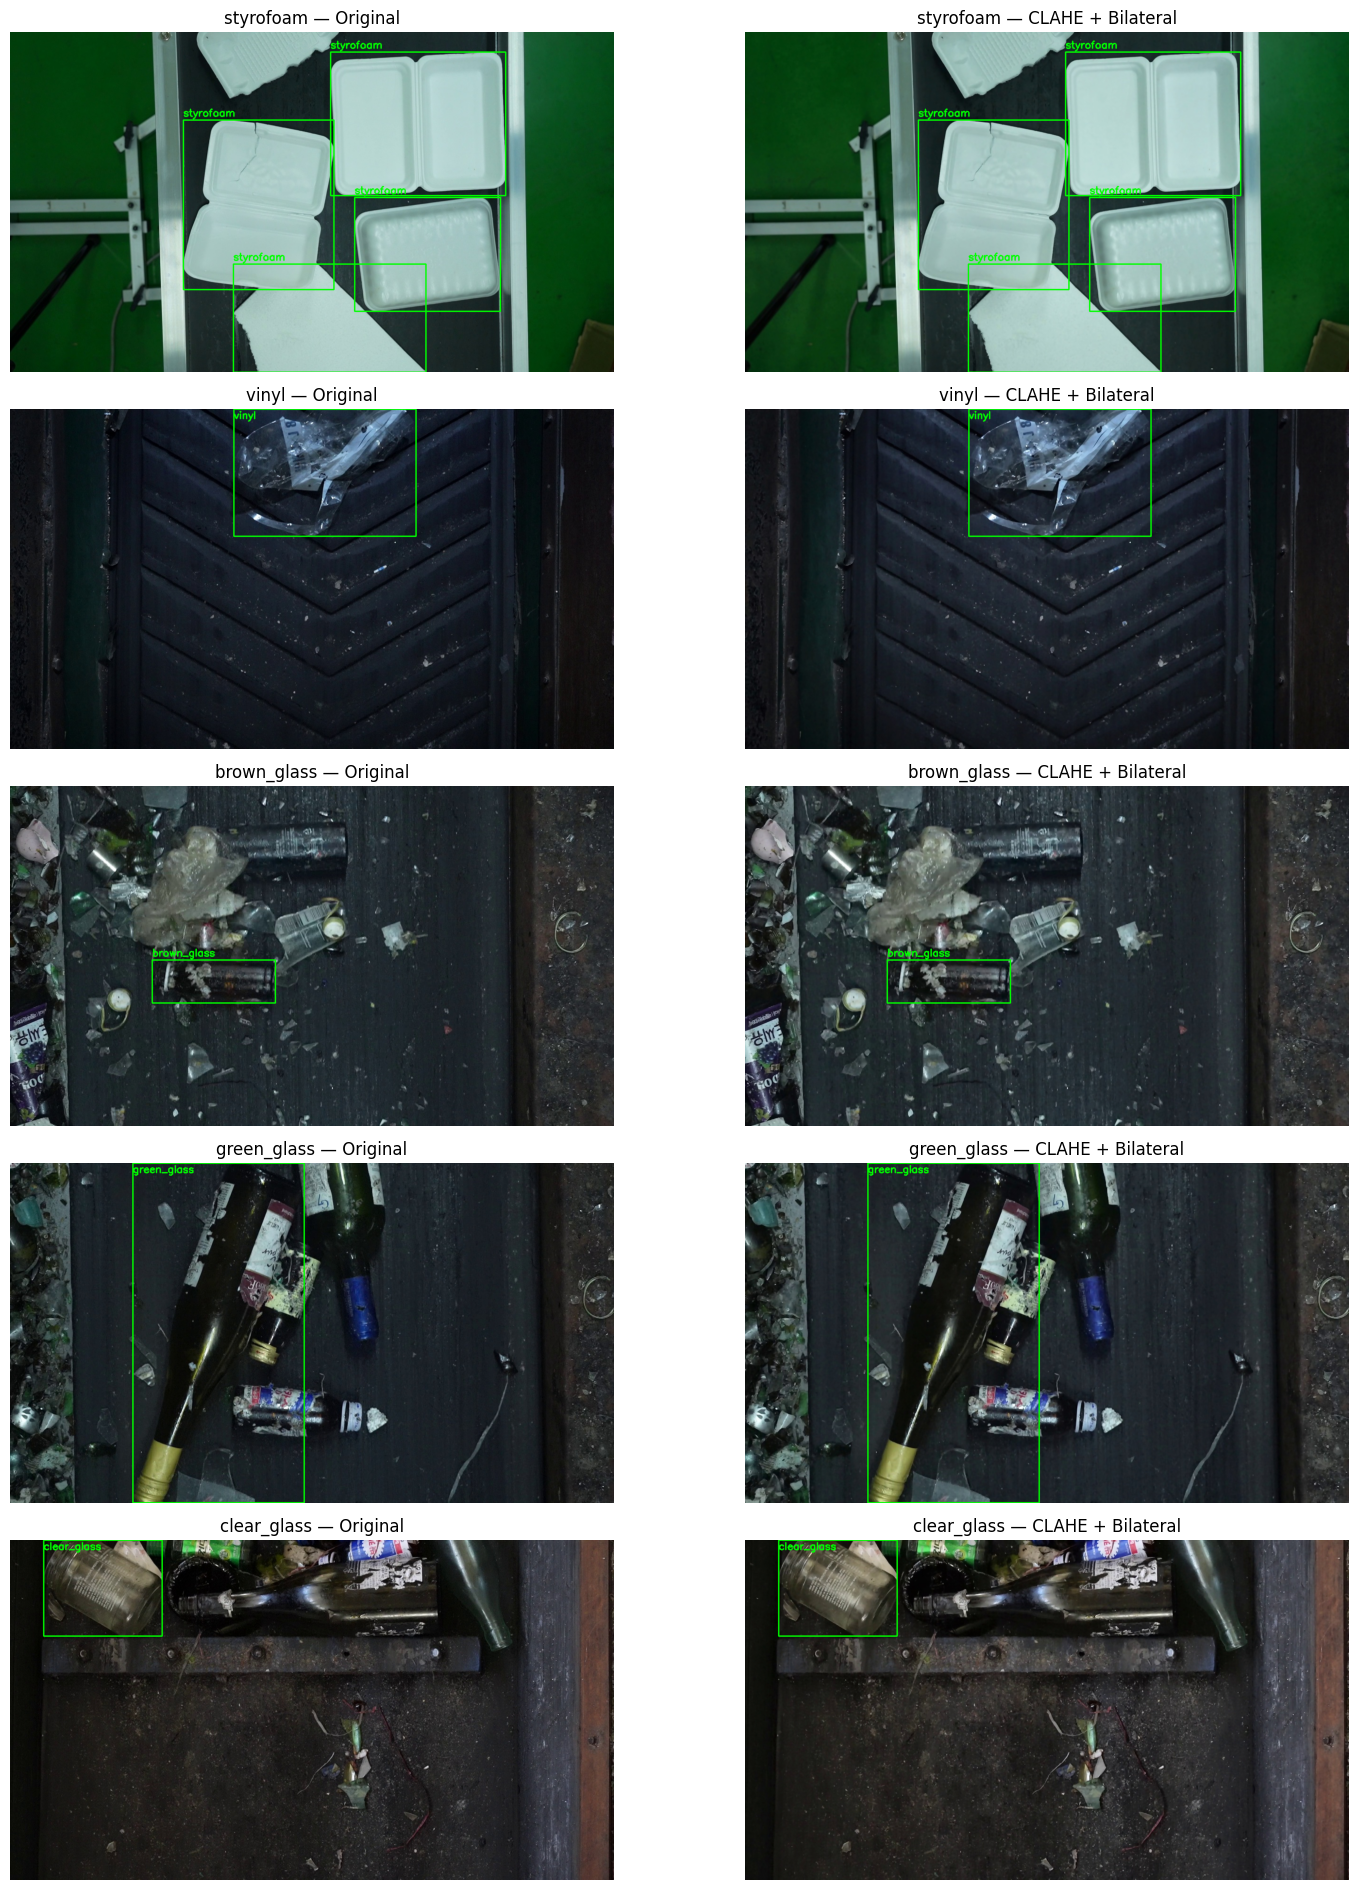

In [14]:

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path("/content/multiclass_yolo26n")
RAW_ROOT = ROOT / "dataset_raw"
CV_ROOT = ROOT / "dataset_opencv"

CLASS_NAMES = {
    0: "styrofoam",
    1: "vinyl",
    2: "brown_glass",
    3: "green_glass",
    4: "clear_glass"
}

# 이미 저장된 Manifest 사용
MANIFEST = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "AI개론/261110스터디/multiclass_yolo26n/"
    "split_manifest.csv"
)

df_selected = pd.read_csv(MANIFEST)

samples = (
    df_selected[df_selected["split"] == "val"]
    .groupby("class_name")
    .sample(n=1, random_state=42)
    .sort_values("class_id")
)

def visualize_yolo(image_path, label_path):
    image = cv2.imread(str(image_path))
    assert image is not None, image_path

    h, w = image.shape[:2]

    for line in Path(label_path).read_text().splitlines():
        cls, cx, cy, bw, bh = map(float, line.split())

        x1 = int((cx - bw / 2) * w)
        y1 = int((cy - bh / 2) * h)
        x2 = int((cx + bw / 2) * w)
        y2 = int((cy + bh / 2) * h)

        cv2.rectangle(
            image, (x1, y1), (x2, y2),
            (0, 255, 0), 2
        )

        cv2.putText(
            image, CLASS_NAMES[int(cls)],
            (x1, max(y1 - 8, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7, (0, 255, 0), 2
        )

    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


fig, axes = plt.subplots(5, 2, figsize=(16, 19))

for i, row in enumerate(samples.itertuples()):
    name = f"{row.class_name}__{Path(row.image_path).stem}"

    for j, (dataset, title) in enumerate([
        (RAW_ROOT, "Original"),
        (CV_ROOT, "CLAHE + Bilateral")
    ]):
        image_path = dataset / "images" / "val" / f"{name}.jpg"
        label_path = dataset / "labels" / "val" / f"{name}.txt"

        axes[i, j].imshow(
            visualize_yolo(image_path, label_path)
        )
        axes[i, j].set_title(f"{row.class_name} — {title}")
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


# YOLO26n 두 모델 연속 학습

In [15]:

%pip -q install ultralytics

from ultralytics import YOLO
from pathlib import Path
import torch
import shutil
import pandas as pd

DEVICE = 0 if torch.cuda.is_available() else "cpu"

SAVE_ROOT = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "AI개론/261110스터디/multiclass_yolo26n"
)

MODEL_DIR = SAVE_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

RUN_ROOT = Path("/content/multiclass_runs")

experiments = [
    ("raw", RAW_ROOT),
    ("opencv", CV_ROOT)
]

results = []

for experiment_name, dataset_root in experiments:

    print(f"\n{'=' * 60}")
    print("학습 시작:", experiment_name)
    print(f"{'=' * 60}")

    yaml_path = dataset_root / "dataset.yaml"
    assert yaml_path.exists(), yaml_path

    model = YOLO("yolo26n.pt")

    model.train(
        data=str(yaml_path),
        epochs=30,
        imgsz=640,
        batch=16,
        device=DEVICE,
        workers=0,

        optimizer="AdamW",
        lr0=0.0006054365855469249,
        weight_decay=0.0002607024758370766,

        mosaic=0.5,
        mixup=0.0,

        # 유리병 색상 정보 보존
        hsv_h=0.0,
        hsv_s=0.0,
        hsv_v=0.0,

        patience=10,
        seed=42,
        deterministic=True,

        project=str(RUN_ROOT),
        name=f"yolo26n_{experiment_name}",
        exist_ok=False,
        verbose=True,
        plots=True
    )

    run_dir = Path(model.trainer.save_dir)
    best_path = run_dir / "weights" / "best.pt"

    assert best_path.exists(), best_path

    saved_path = (
        MODEL_DIR / f"yolo26n_{experiment_name}_best.pt"
    )

    shutil.copy2(best_path, saved_path)

    # 학습 설정과 로그도 보관
    for filename in ["results.csv", "args.yaml"]:
        source = run_dir / filename
        if source.exists():
            shutil.copy2(
                source,
                MODEL_DIR / f"{experiment_name}_{filename}"
            )

    print("저장된 모델:", saved_path)

    # Validation만 평가 (Test는 아직 사용하지 않음)
    trained_model = YOLO(str(saved_path))

    metrics = trained_model.val(
        data=str(yaml_path),
        split="val",
        imgsz=640,
        batch=16,
        device=DEVICE,
        workers=0,
        plots=True,
        verbose=False
    )

    results.append({
        "Model": experiment_name,
        "mAP50": float(metrics.box.map50),
        "mAP50-95": float(metrics.box.map),
        "Precision": float(metrics.box.mp),
        "Recall": float(metrics.box.mr)
    })

    print("Validation 완료:", experiment_name)

df_results = pd.DataFrame(results)

display(df_results)

df_results.to_csv(
    SAVE_ROOT / "validation_comparison.csv",
    index=False
)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings

학습 시작: raw
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/multiclass_yolo26n/dataset_raw/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0

,Model,mAP50,mAP50-95,Precision,Recall
0,raw,0.720017,0.605246,0.622939,0.714569
1,opencv,0.719723,0.608858,0.662310,0.693593


In [16]:

from ultralytics import YOLO
from pathlib import Path
import pandas as pd
import torch

ROOT = Path("/content/multiclass_yolo26n")

SAVE_ROOT = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "AI개론/261110스터디/multiclass_yolo26n"
)

DEVICE = 0 if torch.cuda.is_available() else "cpu"

EXPERIMENTS = {
    "raw": {
        "model": SAVE_ROOT / "models/yolo26n_raw_best.pt",
        "yaml": ROOT / "dataset_raw/dataset.yaml"
    },
    "opencv": {
        "model": SAVE_ROOT / "models/yolo26n_opencv_best.pt",
        "yaml": ROOT / "dataset_opencv/dataset.yaml"
    }
}

TEST_RUNS = SAVE_ROOT / "test_evaluation"
records = []
class_records = []

for name, config in EXPERIMENTS.items():
    print(f"\n===== {name.upper()} TEST =====")

    assert config["model"].exists(), config["model"]
    assert config["yaml"].exists(), config["yaml"]

    model = YOLO(str(config["model"]))

    metrics = model.val(
        data=str(config["yaml"]),
        split="test",
        imgsz=640,
        batch=16,
        device=DEVICE,
        workers=0,
        plots=True,
        project=str(TEST_RUNS),
        name=f"test_{name}",
        exist_ok=True,
        verbose=True
    )

    precision = float(metrics.box.mp)
    recall = float(metrics.box.mr)

    records.append({
        "Model": name,
        "Precision": precision,
        "Recall": recall,
        "mAP50": float(metrics.box.map50),
        "mAP50-95": float(metrics.box.map)
    })

    # 클래스별 성능
    for i, cls_id in enumerate(metrics.box.ap_class_index):
        p = float(metrics.box.p[i])
        r = float(metrics.box.r[i])

        class_records.append({
            "Model": name,
            "Class": model.names[int(cls_id)],
            "Precision": p,
            "Recall": r,
            "F1": 2*p*r/(p+r) if p+r else 0,
            "mAP50": float(metrics.box.ap50[i]),
            "mAP50-95": float(metrics.box.ap[i])
        })

df_test = pd.DataFrame(records)
df_class = pd.DataFrame(class_records)

print("\n===== 최종 TEST 비교 =====")
display(df_test)

print("\n===== 클래스별 TEST 비교 =====")
display(df_class)

df_test.to_csv(
    SAVE_ROOT / "test_model_comparison.csv",
    index=False
)

df_class.to_csv(
    SAVE_ROOT / "test_class_comparison.csv",
    index=False
)

print("\n결과 저장 완료:", SAVE_ROOT)



===== RAW TEST =====
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO26n summary (fused): 121 layers, 2,390,707 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3301.8±909.2 MB/s, size: 305.7 KB)
val: Scanning /content/multiclass_yolo26n/dataset_raw/labels/test... 300 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 300/300 1.4Kit/s 0.2s
val: New cache created: /content/multiclass_yolo26n/dataset_raw/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 4.9it/s 3.8s
                   all        300        622      0.647      0.678       0.71      0.589
             styrofoam         60         78       0.72      0.626      0.734      0.648
                 vinyl         60        206      0.479      0.379      0.401       0.26
           brown_glass         60        154      0.715      0.779      0.795      0.631
           gr

,Model,Precision,Recall,mAP50,mAP50-95
0,raw,0.647277,0.678135,0.710125,0.588978
1,opencv,0.657667,0.641226,0.681757,0.564910



===== 클래스별 TEST 비교 =====


,Model,Class,Precision,Recall,F1,mAP50,mAP50-95
0,raw,styrofoam,0.719817,0.625834,0.669544,0.734148,0.648062
1,raw,vinyl,0.478894,0.378641,0.422907,0.400596,0.260178
2,raw,brown_glass,0.714602,0.779221,0.745514,0.794553,0.631208
3,raw,green_glass,0.573336,0.777778,0.660089,0.783616,0.686205
4,raw,clear_glass,0.749736,0.829199,0.787468,0.837712,0.719236
5,opencv,styrofoam,0.616917,0.525641,0.567633,0.636103,0.561116
6,opencv,vinyl,0.477098,0.447347,0.461744,0.405836,0.260247
7,opencv,brown_glass,0.786567,0.733766,0.759250,0.779001,0.636130
8,opencv,green_glass,0.660714,0.708333,0.683696,0.765921,0.663226
9,opencv,clear_glass,0.747038,0.791044,0.768411,0.821926,0.703831



결과 저장 완료: /content/drive/MyDrive/Colab Notebooks/AI개론/261110스터디/multiclass_yolo26n


# Multi-task 학습을 위한 속성 분포 분석

In [17]:

import json
import pandas as pd
from collections import Counter, defaultdict
from tqdm.auto import tqdm

ATTRIBUTES = [
    "DAMAGE",
    "DIRTINESS",
    "COVER",
    "TRANSPARENCY",
    "SHAPE"
]

attribute_stats = defaultdict(Counter)
class_attribute_stats = defaultdict(Counter)
missing_stats = defaultdict(Counter)

trainval = df_selected[
    df_selected["split"].isin(["train", "val"])
].copy()

for row in tqdm(
    trainval.itertuples(index=False),
    total=len(trainval),
    desc="Multi-task 속성 분석",
    unit="img"
):
    with open(row.label_path, encoding="utf-8-sig") as f:
        data = json.load(f)

    for obj in data.get("ANNOTATION_INFO", []):
        for attr in ATTRIBUTES:
            value = obj.get(attr)

            if value is None or str(value).strip() == "":
                missing_stats[row.class_name][attr] += 1
                continue

            value = str(value).strip()

            attribute_stats[attr][value] += 1
            class_attribute_stats[
                (row.class_name, attr)
            ][value] += 1

for attr in ATTRIBUTES:
    print(f"\n===== {attr} =====")

    df_attr = pd.DataFrame(
        attribute_stats[attr].most_common(),
        columns=["Value", "Count"]
    )

    display(df_attr)

    print("고유 값:", len(attribute_stats[attr]))

print("\n===== 클래스별 속성 종류 =====")

records = []

for (class_name, attr), counter in class_attribute_stats.items():
    records.append({
        "Class": class_name,
        "Attribute": attr,
        "Unique Values": len(counter),
        "Total Objects": sum(counter.values()),
        "Top Values": str(counter.most_common(5))
    })

df_attribute_summary = pd.DataFrame(records)

display(
    df_attribute_summary.sort_values(
        ["Attribute", "Class"]
    )
)


Multi-task 속성 분석:   0%|          | 0/1700 [00:00<?, ?img/s]


===== DAMAGE =====


,Value,Count
0,원형,2868
1,파손,451
2,찢어짐,438
3,찌그러짐,3


고유 값: 4

===== DIRTINESS =====


,Value,Count
0,이물질(외부),1973
1,오염없음,1589
2,이물질(내부),117
3,이물질(전체),81


고유 값: 4

===== COVER =====


... (3 outputs left out)

고유 값: 2

===== SHAPE =====


,Value,Count
0,유리병형,1925
1,봉지형,769
2,식품용기형,700
3,기타 형태,293
4,내장재용도형,64
5,박스형,7
6,원형용기형,1
7,중간 원통형,1


고유 값: 8

===== 클래스별 속성 종류 =====


,Class,Attribute,Unique Values,Total Objects,Top Values
2,brown_glass,COVER,2,890,"[('없음', 867), ('겹침', 23)]"
7,clear_glass,COVER,2,590,"[('없음', 538), ('겹침', 52)]"
12,green_glass,COVER,2,468,"[('없음', 438), ('겹침', 30)]"
17,styrofoam,COVER,2,794,"[('없음', 543), ('겹침', 251)]"
22,vinyl,COVER,2,1018,"[('겹침', 509), ('없음', 509)]"
0,brown_glass,DAMAGE,2,890,"[('원형', 865), ('파손', 25)]"
5,clear_glass,DAMAGE,2,590,"[('원형', 520), ('파손', 70)]"
10,green_glass,DAMAGE,2,468,"[('원형', 415), ('파손', 53)]"
15,styrofoam,DAMAGE,2,794,"[('원형', 491), ('파손', 303)]"
20,vinyl,DAMAGE,3,1018,"[('원형', 577), ('찢어짐', 438), ('찌그러짐', 3)]"


# CNN 학습용 ROI 데이터

In [18]:

import cv2
import json
import numpy as np
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm
from collections import Counter

ROOT = Path("/content/multiclass_yolo26n")
RAW_ROOT = ROOT / "dataset_raw"
ROI_ROOT = ROOT / "roi_multitask"

MANIFEST = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "AI개론/261110스터디/"
    "multiclass_yolo26n/split_manifest.csv"
)

df_selected = pd.read_csv(MANIFEST)

CLASS_MAP = {
    ("스티로폼", "스티로폼"): 0,
    ("비닐", "비닐"): 1,
    ("유리병", "갈색"): 2,
    ("유리병", "녹색"): 3,
    ("유리병", "투명"): 4
}

def encode_attributes(obj):
    damage = str(obj.get("DAMAGE", "")).strip()
    dirt = str(obj.get("DIRTINESS", "")).strip()
    cover = str(obj.get("COVER", "")).strip()
    transparency = str(obj.get("TRANSPARENCY", "")).strip()

    assert damage in {
        "원형", "파손", "찢어짐", "찌그러짐"
    }, damage

    assert dirt in {
        "오염없음", "이물질(외부)",
        "이물질(내부)", "이물질(전체)"
    }, dirt

    assert cover in {"없음", "겹침"}, cover
    assert transparency in {"불투명", "투명"}, transparency

    return {
        "damage": int(damage != "원형"),
        "dirtiness": int(dirt != "오염없음"),
        "cover": int(cover == "겹침"),
        "transparency": int(transparency == "투명")
    }


def letterbox_roi(image, size=224):
    h, w = image.shape[:2]
    scale = min(size / w, size / h)

    nw = max(1, round(w * scale))
    nh = max(1, round(h * scale))

    resized = cv2.resize(
        image, (nw, nh),
        interpolation=cv2.INTER_AREA
        if scale < 1 else cv2.INTER_LINEAR
    )

    canvas = np.full(
        (size, size, 3), 114,
        dtype=np.uint8
    )

    x = (size - nw) // 2
    y = (size - nh) // 2

    canvas[y:y+nh, x:x+nw] = resized
    return canvas


def preprocess_roi(image):
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=1.5,
        tileGridSize=(8, 8)
    )

    enhanced_l = clahe.apply(l)

    l = cv2.addWeighted(
        l, 0.65, enhanced_l, 0.35, 0
    )

    enhanced = cv2.cvtColor(
        cv2.merge([l, a, b]),
        cv2.COLOR_LAB2BGR
    )

    return cv2.bilateralFilter(
        enhanced,
        d=5,
        sigmaColor=30,
        sigmaSpace=30
    )


records = []
stats = Counter()

trainval = df_selected[
    df_selected["split"].isin(["train", "val"])
].copy()

for row in tqdm(
    trainval.itertuples(index=False),
    total=len(trainval),
    desc="Multi-task ROI 생성",
    unit="image",
    dynamic_ncols=True
):
    split = row.split
    stem = f"{row.class_name}__{Path(row.image_path).stem}"

    img_path = RAW_ROOT / "images" / split / f"{stem}.jpg"
    yolo_path = RAW_ROOT / "labels" / split / f"{stem}.txt"

    image = cv2.imread(str(img_path))
    if image is None:
        raise FileNotFoundError(img_path)

    with open(row.label_path, encoding="utf-8-sig") as f:
        data = json.load(f)

    objects = data.get("ANNOTATION_INFO", [])
    yolo_lines = yolo_path.read_text().splitlines()

    # 앞선 변환에서 유효하지 않은 라벨 0개였으므로
    # JSON 순서와 YOLO 라벨 순서가 일치해야 함
    if len(objects) != len(yolo_lines):
        raise ValueError(
            f"객체/YOLO 라벨 개수 불일치: {stem}"
        )

    H, W = image.shape[:2]

    for obj_idx, (obj, line) in enumerate(
        zip(objects, yolo_lines)
    ):
        values = list(map(float, line.split()))

        cls_id = int(values[0])
        cx, cy, bw, bh = values[1:5]

        expected_cls = CLASS_MAP.get(
            (obj.get("CLASS"), obj.get("DETAILS"))
        )

        if cls_id != expected_cls:
            raise ValueError(
                f"클래스 불일치: {stem}/{obj_idx}"
            )

        # 정규화된 YOLO 박스를 픽셀 좌표로 복원
        x1 = (cx - bw / 2) * W
        y1 = (cy - bh / 2) * H
        x2 = (cx + bw / 2) * W
        y2 = (cy + bh / 2) * H

        # 객체 주변 8% 여백
        margin = 0.08 * max(x2-x1, y2-y1)

        x1 = max(0, int(x1-margin))
        y1 = max(0, int(y1-margin))
        x2 = min(W, int(np.ceil(x2+margin)))
        y2 = min(H, int(np.ceil(y2+margin)))

        if x2 <= x1 or y2 <= y1:
            raise ValueError(f"잘못된 ROI: {stem}/{obj_idx}")

        crop = image[y1:y2, x1:x2]

        raw_roi = letterbox_roi(crop)
        cv_roi = preprocess_roi(raw_roi)

        name = f"{stem}__obj{obj_idx:03d}.jpg"

        for variant, roi in [
            ("raw", raw_roi),
            ("opencv", cv_roi)
        ]:
            output_dir = ROI_ROOT / variant / split
            output_dir.mkdir(parents=True, exist_ok=True)

            output = output_dir / name

            if not cv2.imwrite(str(output), roi):
                raise RuntimeError(f"저장 실패: {output}")

        attrs = encode_attributes(obj)

        records.append({
            "split": split,
            "filename": name,
            "class_id": cls_id,
            "group_id": row.group_id,
            **attrs
        })

        stats[f"{split}_objects"] += 1


df_roi = pd.DataFrame(records)

ROI_MANIFEST = ROI_ROOT / "roi_manifest.csv"

df_roi.to_csv(
    ROI_MANIFEST,
    index=False,
    encoding="utf-8-sig"
)

print("\n===== ROI 생성 완료 =====")
print("Train 객체:", stats["train_objects"])
print("Val 객체:", stats["val_objects"])
print("전체 ROI:", len(df_roi))
print("Raw ROI:", ROI_ROOT / "raw")
print("OpenCV ROI:", ROI_ROOT / "opencv")

display(pd.crosstab(
    df_roi["class_id"],
    df_roi["split"]
))

assert len(df_roi) == 3760, (
    f"예상 객체 3760개, 실제 {len(df_roi)}개"
)


Multi-task ROI 생성:   0%|          | 0/1700 [00:00<?, ?image/s]


===== ROI 생성 완료 =====
Train 객체: 3088
Val 객체: 672
전체 ROI: 3760
Raw ROI: /content/multiclass_yolo26n/roi_multitask/raw
OpenCV ROI: /content/multiclass_yolo26n/roi_multitask/opencv


split,train,val
class_id,,
0,627,167
1,851,167
2,729,161
3,385,83
4,496,94


# Multi-task 데이터셋 및 DataLoader

In [26]:

# ============================================================
# Cell 1. 환경 설정 / ROI Dataset / DataLoader
# ============================================================

import random
import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import (
    resnet18,
    ResNet18_Weights
)

from sklearn.metrics import (
    accuracy_score,
    f1_score
)

# ============================================================
# 1. 실험 설정
# ============================================================

SEED = 42
BATCH_SIZE = 32
EPOCHS = 20
PATIENCE = 5

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

# ============================================================
# 2. 데이터 경로
# ============================================================

ROOT = Path("/content/multiclass_yolo26n")

ROI_ROOT = ROOT / "roi_multitask"

SAVE_ROOT = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "AI개론/261110스터디/multiclass_yolo26n"
)

MODEL_DIR = SAVE_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

ROI_MANIFEST = ROI_ROOT / "roi_manifest.csv"

assert ROI_MANIFEST.exists(), (
    f"ROI Manifest가 없습니다: {ROI_MANIFEST}"
)

# ============================================================
# 3. Multi-task 출력 정의
# ============================================================

HEAD_DIMS = {
    "class_id": 5,
    "damage": 2,
    "dirtiness": 2,
    "cover": 2,
    "transparency": 2
}

CLASS_NAMES = {
    0: "styrofoam",
    1: "vinyl",
    2: "brown_glass",
    3: "green_glass",
    4: "clear_glass"
}

# ============================================================
# 4. ROI Manifest 로딩
# ============================================================

df_roi = pd.read_csv(ROI_MANIFEST)

train_df = (
    df_roi[df_roi["split"] == "train"]
    .reset_index(drop=True)
)

val_df = (
    df_roi[df_roi["split"] == "val"]
    .reset_index(drop=True)
)

assert len(train_df) == 3088, len(train_df)
assert len(val_df) == 672, len(val_df)

# 클래스별 라벨 검증
for head, n_classes in HEAD_DIMS.items():

    for name, frame in [
        ("train", train_df),
        ("val", val_df)
    ]:

        assert frame[head].notna().all(), (
            name, head, "결측값 존재"
        )

        assert frame[head].between(
            0, n_classes - 1
        ).all(), (
            name, head, "잘못된 클래스 ID"
        )

# 촬영 그룹 누수 검사
train_groups = set(train_df["group_id"])
val_groups = set(val_df["group_id"])

assert train_groups.isdisjoint(val_groups), (
    "Train과 Validation 그룹이 중복됩니다."
)

# ============================================================
# 5. ImageNet 전처리
# ============================================================

normalize = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    normalize
])

val_transform = transforms.Compose([
    transforms.ToTensor(),
    normalize
])

# ============================================================
# 6. PyTorch Dataset
# ============================================================

class MultiTaskDataset(Dataset):

    def __init__(
        self,
        dataframe,
        variant,
        transform
    ):
        self.df = dataframe.reset_index(drop=True)
        self.variant = variant
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_path = (
            ROI_ROOT
            / self.variant
            / row["split"]
            / row["filename"]
        )

        if not image_path.exists():
            raise FileNotFoundError(image_path)

        with Image.open(image_path) as image:
            image = image.convert("RGB")

        image = self.transform(image)

        targets = {
            head: torch.tensor(
                int(row[head]),
                dtype=torch.long
            )
            for head in HEAD_DIMS
        }

        return image, targets


# ============================================================
# 7. DataLoader
# 핵심 수정: num_workers=0 / pin_memory=False
# ============================================================

def create_loaders(variant):

    if variant not in {"raw", "opencv"}:
        raise ValueError(variant)

    train_dataset = MultiTaskDataset(
        train_df,
        variant,
        train_transform
    )

    val_dataset = MultiTaskDataset(
        val_df,
        variant,
        val_transform
    )

    generator = torch.Generator()
    generator.manual_seed(SEED)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=False,
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=False
    )

    return train_loader, val_loader


# ============================================================
# 8. 동작 확인
# ============================================================

train_loader, val_loader = create_loaders("raw")

images, targets = next(iter(train_loader))

print("===== 환경 확인 =====")
print("Device:", DEVICE)
print("Train ROI:", len(train_df))
print("Validation ROI:", len(val_df))
print("Image batch:", images.shape)
print("Target heads:", list(targets.keys()))
print("DataLoader workers:", train_loader.num_workers)

print("\n===== 클래스별 ROI =====")

display(pd.crosstab(
    df_roi["class_id"],
    df_roi["split"]
))

print("\nCell 1 완료!")


===== 환경 확인 =====
Device: cuda
Train ROI: 3088
Validation ROI: 672
Image batch: torch.Size([32, 3, 224, 224])
Target heads: ['class_id', 'damage', 'dirtiness', 'cover', 'transparency']
DataLoader workers: 0

===== 클래스별 ROI =====


split,train,val
class_id,,
0,627,167
1,851,167
2,729,161
3,385,83
4,496,94



Cell 1 완료!


# ResNet18 기반 Multi-task CNN

In [27]:

# ============================================================
# Cell 2. Multi-task ResNet18 / Loss / Validation
# ============================================================

import numpy as np
import torch
import torch.nn as nn

from torchvision.models import (
    resnet18,
    ResNet18_Weights
)

from sklearn.metrics import (
    accuracy_score,
    f1_score
)

# ============================================================
# 1. Multi-task CNN 모델
# ============================================================

class MultiTaskResNet18(nn.Module):

    def __init__(self):
        super().__init__()

        # ImageNet 사전학습 백본
        self.backbone = resnet18(
            weights=ResNet18_Weights.DEFAULT
        )

        feature_dim = self.backbone.fc.in_features

        # 기존 ResNet 분류기 제거
        self.backbone.fc = nn.Identity()

        # 5개의 출력 헤드
        self.heads = nn.ModuleDict({

            name: nn.Sequential(
                nn.Dropout(p=0.2),
                nn.Linear(
                    feature_dim,
                    num_classes
                )
            )

            for name, num_classes in HEAD_DIMS.items()
        })

    def forward(self, x):

        features = self.backbone(x)

        outputs = {
            name: head(features)
            for name, head in self.heads.items()
        }

        return outputs


# ============================================================
# 2. Class Weight 계산
# Train 데이터만 사용
# ============================================================

def create_loss_functions():

    loss_functions = {}

    for head, n_classes in HEAD_DIMS.items():

        counts = np.bincount(
            train_df[head].to_numpy(dtype=int),
            minlength=n_classes
        )

        # 불균형 완화용 sqrt inverse frequency
        weights = np.sqrt(
            counts.sum() /
            (n_classes * np.maximum(counts, 1))
        )

        # 지나치게 큰 가중치 방지
        weights = np.clip(
            weights,
            0.5,
            3.0
        )

        weights = weights / weights.mean()

        weight_tensor = torch.tensor(
            weights,
            dtype=torch.float32,
            device=DEVICE
        )

        loss_functions[head] = nn.CrossEntropyLoss(
            weight=weight_tensor
        )

        print(
            f"{head:15s} | "
            f"counts={counts.tolist()} | "
            f"weights={np.round(weights, 3)}"
        )

    return loss_functions


LOSS_FUNCTIONS = create_loss_functions()

# ============================================================
# 3. Task별 손실 가중치
# ============================================================

TASK_WEIGHTS = {
    "class_id": 1.0,
    "damage": 1.0,
    "dirtiness": 1.0,
    "cover": 1.0,
    "transparency": 1.0
}


def multitask_loss(outputs, targets):

    total_loss = torch.zeros(
        (),
        device=DEVICE
    )

    total_weight = sum(TASK_WEIGHTS.values())

    for head in HEAD_DIMS:

        loss = LOSS_FUNCTIONS[head](
            outputs[head],
            targets[head]
        )

        total_loss = (
            total_loss +
            TASK_WEIGHTS[head] * loss
        )

    return total_loss / total_weight


# ============================================================
# 4. Validation 평가 함수
# ============================================================

@torch.inference_mode()
def evaluate_multitask(model, loader):

    model.eval()

    running_loss = 0.0
    total_samples = 0

    true_labels = {
        head: [] for head in HEAD_DIMS
    }

    pred_labels = {
        head: [] for head in HEAD_DIMS
    }

    for images, targets in loader:

        images = images.to(DEVICE)

        targets = {
            head: tensor.to(DEVICE)
            for head, tensor in targets.items()
        }

        outputs = model(images)

        loss = multitask_loss(
            outputs,
            targets
        )

        batch_size = images.size(0)

        running_loss += loss.item() * batch_size
        total_samples += batch_size

        for head in HEAD_DIMS:

            true_labels[head].extend(
                targets[head].cpu().tolist()
            )

            predictions = (
                outputs[head]
                .argmax(dim=1)
                .cpu()
                .tolist()
            )

            pred_labels[head].extend(predictions)

    metrics = {
        "loss": running_loss / total_samples
    }

    # 5개 태스크별 Accuracy / Macro-F1
    for head, n_classes in HEAD_DIMS.items():

        y_true = true_labels[head]
        y_pred = pred_labels[head]

        metrics[f"{head}_accuracy"] = (
            accuracy_score(y_true, y_pred)
        )

        metrics[f"{head}_f1"] = f1_score(
            y_true,
            y_pred,
            labels=list(range(n_classes)),
            average="macro",
            zero_division=0
        )

    # 전체 태스크 Macro-F1 평균
    metrics["mean_macro_f1"] = float(
        np.mean([
            metrics[f"{head}_f1"]
            for head in HEAD_DIMS
        ])
    )

    return metrics


# ============================================================
# 5. 모델 출력 구조 테스트
# ============================================================

model = MultiTaskResNet18().to(DEVICE)
model.eval()

with torch.inference_mode():
    dummy = torch.randn(
        2, 3, 224, 224,
        device=DEVICE
    )

    outputs = model(dummy)

print("\n===== 모델 출력 구조 =====")

for head, tensor in outputs.items():
    print(
        f"{head:15s}: {tuple(tensor.shape)}"
    )

# 메모리 정리
del model, dummy, outputs

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\nCell 2 완료!")


class_id        | counts=[627, 851, 729, 385, 496] | weights=[      0.964       0.828       0.894        1.23       1.084]
damage          | counts=[2340, 748] | weights=[      0.722       1.278]
dirtiness       | counts=[1288, 1800] | weights=[      1.083       0.917]
cover           | counts=[2357, 731] | weights=[      0.715       1.285]
transparency    | counts=[2426, 662] | weights=[      0.686       1.314]

===== 모델 출력 구조 =====
class_id       : (2, 5)
damage         : (2, 2)
dirtiness      : (2, 2)
cover          : (2, 2)
transparency   : (2, 2)

Cell 2 완료!


# 학습, 진행률, Early Stopping, 평가 및 저장

In [28]:

# ============================================================
# Cell 3. Multi-task CNN 학습 / Checkpoint / Early Stopping
# ============================================================

import gc
import random
import numpy as np
import pandas as pd
import torch
import torch.optim as optim

from pathlib import Path
from tqdm.auto import tqdm

# ============================================================
# 1. 학습 함수
# ============================================================

def train_variant(variant):

    if variant not in {"raw", "opencv"}:
        raise ValueError(variant)

    print("\n" + "=" * 65)
    print(f"Multi-task CNN 학습: {variant.upper()}")
    print("=" * 65)

    seed_everything(SEED)

    # --------------------------------------------------------
    # DataLoader
    # --------------------------------------------------------

    train_loader, val_loader = create_loaders(
        variant
    )

    print("Train batches:", len(train_loader))
    print("Val batches:", len(val_loader))
    print("Workers:", train_loader.num_workers)

    # --------------------------------------------------------
    # 모델
    # --------------------------------------------------------

    model = MultiTaskResNet18().to(DEVICE)

    # 차등 학습률
    optimizer = optim.AdamW(
        [
            {
                "params": model.backbone.parameters(),
                "lr": 1e-4
            },
            {
                "params": model.heads.parameters(),
                "lr": 5e-4
            }
        ],
        weight_decay=1e-4
    )

    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=EPOCHS
    )

    use_amp = DEVICE.type == "cuda"

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=use_amp
    )

    # --------------------------------------------------------
    # 체크포인트 경로
    # --------------------------------------------------------

    best_path = (
        MODEL_DIR /
        f"resnet18_multitask_{variant}_best.pt"
    )

    last_path = (
        MODEL_DIR /
        f"resnet18_multitask_{variant}_last.pt"
    )

    history_path = (
        SAVE_ROOT /
        f"multitask_{variant}_history.csv"
    )

    best_score = -1.0
    best_epoch = 0
    bad_epochs = 0
    start_epoch = 1

    history = []

    # --------------------------------------------------------
    # 중단된 학습 이어서 실행
    # --------------------------------------------------------

    if last_path.exists():

        print("\n이전 학습 상태 발견!")

        checkpoint = torch.load(
            last_path,
            map_location=DEVICE,
            weights_only=True
        )

        model.load_state_dict(
            checkpoint["model_state"]
        )

        optimizer.load_state_dict(
            checkpoint["optimizer_state"]
        )

        scheduler.load_state_dict(
            checkpoint["scheduler_state"]
        )

        scaler.load_state_dict(
            checkpoint["scaler_state"]
        )

        start_epoch = int(
            checkpoint["epoch"]
        ) + 1

        best_score = float(
            checkpoint["best_score"]
        )

        best_epoch = int(
            checkpoint["best_epoch"]
        )

        bad_epochs = int(
            checkpoint["bad_epochs"]
        )

        if history_path.exists():
            history = pd.read_csv(
                history_path
            ).to_dict("records")

        print("재개 Epoch:", start_epoch)
        print("기존 Best Epoch:", best_epoch)
        print("기존 Best Score:", best_score)

    # --------------------------------------------------------
    # Epoch 반복
    # --------------------------------------------------------

    for epoch in range(start_epoch, EPOCHS + 1):

        model.train()

        running_loss = 0.0
        n_seen = 0

        progress = tqdm(
            train_loader,
            desc=(
                f"{variant.upper()} "
                f"Epoch {epoch:02d}/{EPOCHS}"
            ),
            unit="batch",
            dynamic_ncols=True,
            leave=False
        )

        # ----------------------------------------------------
        # Mini-batch 학습
        # ----------------------------------------------------

        for images, targets in progress:

            images = images.to(DEVICE)

            targets = {
                head: tensor.to(DEVICE)
                for head, tensor in targets.items()
            }

            optimizer.zero_grad(
                set_to_none=True
            )

            with torch.autocast(
                device_type=DEVICE.type,
                enabled=use_amp
            ):

                outputs = model(images)

                loss = multitask_loss(
                    outputs,
                    targets
                )

            scaler.scale(loss).backward()

            scaler.step(optimizer)
            scaler.update()

            batch_size = images.size(0)

            running_loss += (
                loss.item() * batch_size
            )

            n_seen += batch_size

            progress.set_postfix(
                train_loss=(
                    f"{running_loss/n_seen:.4f}"
                )
            )

        train_loss = running_loss / n_seen

        # ----------------------------------------------------
        # Validation
        # ----------------------------------------------------

        val_metrics = evaluate_multitask(
            model,
            val_loader
        )

        score = val_metrics["mean_macro_f1"]

        scheduler.step()

        # ----------------------------------------------------
        # 기록
        # ----------------------------------------------------

        epoch_record = {
            "epoch": epoch,
            "train_loss": train_loss,
            **val_metrics
        }

        history.append(epoch_record)

        df_history = pd.DataFrame(history)

        # 매 Epoch 기록 보존
        df_history.to_csv(
            history_path,
            index=False
        )

        print(
            f"[{variant}] "
            f"Epoch {epoch:02d} | "
            f"Train {train_loss:.4f} | "
            f"Val {val_metrics['loss']:.4f} | "
            f"Mean-F1 {score:.4f}"
        )

        print(
            "  Class:",
            f"{val_metrics['class_id_f1']:.4f}",
            "| Damage:",
            f"{val_metrics['damage_f1']:.4f}",
            "| Dirt:",
            f"{val_metrics['dirtiness_f1']:.4f}",
            "| Cover:",
            f"{val_metrics['cover_f1']:.4f}",
            "| Transparency:",
            f"{val_metrics['transparency_f1']:.4f}"
        )

        # ----------------------------------------------------
        # 최고 모델 저장
        # ----------------------------------------------------

        if score > best_score + 1e-4:

            best_score = score
            best_epoch = epoch
            bad_epochs = 0

            torch.save(
                {
                    "model_state": model.state_dict(),
                    "epoch": epoch,
                    "variant": variant,
                    "val_metrics": val_metrics,
                    "head_dims": HEAD_DIMS,
                    "class_names": CLASS_NAMES
                },
                best_path
            )

            print("  ✓ Best checkpoint 저장")

        else:
            bad_epochs += 1

        # ----------------------------------------------------
        # 마지막 학습 상태 저장
        # ----------------------------------------------------

        torch.save(
            {
                "model_state": model.state_dict(),
                "optimizer_state": optimizer.state_dict(),
                "scheduler_state": scheduler.state_dict(),
                "scaler_state": scaler.state_dict(),
                "epoch": epoch,
                "best_score": best_score,
                "best_epoch": best_epoch,
                "bad_epochs": bad_epochs,
                "variant": variant
            },
            last_path
        )

        # ----------------------------------------------------
        # Early Stopping
        # ----------------------------------------------------

        if bad_epochs >= PATIENCE:

            print(
                "\nEarly Stopping! "
                f"{PATIENCE} Epoch 동안 "
                "Validation 성능 개선 없음."
            )

            break

    # --------------------------------------------------------
    # 최종 최고 모델 평가
    # --------------------------------------------------------

    assert best_path.exists(), (
        f"Best checkpoint 없음: {best_path}"
    )

    best_checkpoint = torch.load(
        best_path,
        map_location=DEVICE,
        weights_only=True
    )

    model.load_state_dict(
        best_checkpoint["model_state"]
    )

    best_metrics = evaluate_multitask(
        model,
        val_loader
    )

    print("\n" + "=" * 65)
    print(f"{variant.upper()} 학습 결과")
    print("=" * 65)

    print("Best Epoch:", best_checkpoint["epoch"])
    print(
        "Best Mean Macro-F1:",
        f"{best_metrics['mean_macro_f1']:.4f}"
    )

    print("Best Model:", best_path)
    print("Last Checkpoint:", last_path)

    result = {
        "Model": variant,
        "Best Epoch": int(best_checkpoint["epoch"]),
        **best_metrics
    }

    # GPU 메모리 정리
    del model
    del optimizer
    del scheduler
    del scaler

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result


print("Cell 3 완료! 학습 함수 준비됨.")


Cell 3 완료! 학습 함수 준비됨.


In [30]:

# ============================================================
# Cell 4. RAW 복구 / OpenCV 학습 / 최종 비교
# ============================================================

import torch
import pandas as pd
from pathlib import Path
from IPython.display import display

# ============================================================
# 1. 기존 RAW 모델 체크포인트 확인
# ============================================================

RAW_BEST_PATH = (
    MODEL_DIR /
    "resnet18_multitask_raw_best.pt"
)

assert RAW_BEST_PATH.exists(), (
    f"기존 RAW 모델을 찾을 수 없습니다: "
    f"{RAW_BEST_PATH}"
)

# 직접 학습하고 신뢰할 수 있는 파일이므로 weights_only=False로 설정하여 NumPy 스칼라 등 메타데이터까지 함께 복구합니다.
raw_checkpoint = torch.load(
    RAW_BEST_PATH,
    map_location=DEVICE,
    weights_only=False
)

print("=" * 65)
print("기존 RAW Multi-task 모델 복구")
print("=" * 65)

print(
    "Best Epoch:",
    raw_checkpoint["epoch"]
)

print(
    "Saved Variant:",
    raw_checkpoint["variant"]
)

# ============================================================
# 2. RAW 최고 모델 다시 Validation 평가
# ============================================================

raw_model = MultiTaskResNet18().to(DEVICE)

raw_model.load_state_dict(
    raw_checkpoint["model_state"]
)

raw_model.eval()

_, raw_val_loader = create_loaders("raw")

raw_metrics = evaluate_multitask(
    raw_model,
    raw_val_loader
)

raw_result = {
    "Model": "raw",
    "Best Epoch": int(raw_checkpoint["epoch"]),
    **raw_metrics
}

print("\n===== RAW Validation 결과 =====")

for key, value in raw_metrics.items():
    print(f"{key:25s}: {value:.4f}")

del raw_model

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# ============================================================
# 3. OpenCV Multi-task CNN 학습
# ============================================================

print("\n" + "=" * 65)
print("OpenCV Multi-task CNN 학습 시작")
print("=" * 65)

opencv_result = train_variant("opencv")

# ============================================================
# 4. 최종 비교
# ============================================================

df_comparison = pd.DataFrame([
    raw_result,
    opencv_result
])

print("\n===== RAW vs OpenCV =====")

display(df_comparison.T)

# ============================================================
# 5. 태스크별 Macro-F1 비교
# ============================================================

heads = [
    "class_id",
    "damage",
    "dirtiness",
    "cover",
    "transparency"
]

comparison_rows = []

for head in heads:

    raw_f1 = raw_result[f"{head}_f1"]
    opencv_f1 = opencv_result[f"|{head}_f1" if f"|{head}_f1" in opencv_result else f"{head}_f1"]

    comparison_rows.append({
        "Task": head,
        "Raw Macro-F1": raw_f1,
        "OpenCV Macro-F1": opencv_f1,
        "Difference": opencv_f1 - raw_f1
    })

df_task_comparison = pd.DataFrame(
    comparison_rows
)

print("\n===== 태스크별 비교 =====")

display(df_task_comparison)

# ============================================================
# 6. Validation 최고 모델 확인
# ============================================================

best_variant = max(
    [raw_result, opencv_result],
    key=lambda x: x["mean_macro_f1"]
)

print("\n===== Validation 기준 최고 모델 =====")
print("Model:", best_variant["Model"])
print(
    "Mean Macro-F1:",
    f"{best_variant["mean_macro_f1"]:.4f}"
)

# ============================================================
# 7. CSV 결과 저장
# ============================================================

comparison_path = (
    SAVE_ROOT /
    "multitask_validation_comparison.csv"
)

task_comparison_path = (
    SAVE_ROOT /
    "multitask_task_comparison.csv"
)

df_comparison.to_csv(
    comparison_path,
    index=False,
    encoding="utf-8-sig"
)

df_task_comparison.to_csv(
    task_comparison_path,
    index=False,
    encoding="utf-8-sig"
)

print("\n===== 저장 완료 =====")
print("전체 비교:", comparison_path)
print("태스크별 비교:", task_comparison_path)

print("\nMulti-task CNN 학습 및 비교 완료!")


기존 RAW Multi-task 모델 복구
Best Epoch: 8
Saved Variant: raw

===== RAW Validation 결과 =====
loss                     : 0.4436
class_id_accuracy        : 0.9509
class_id_f1              : 0.9398
damage_accuracy          : 0.7798
damage_f1                : 0.6570
dirtiness_accuracy       : 0.9315
dirtiness_f1             : 0.9311
cover_accuracy           : 0.8065
cover_f1                 : 0.7262
transparency_accuracy    : 0.9360
transparency_f1          : 0.8836
mean_macro_f1            : 0.8275

OpenCV Multi-task CNN 학습 시작

Multi-task CNN 학습: OPENCV
Train batches: 97
Val batches: 21
Workers: 0


OPENCV Epoch 01/20:   0%|          | 0/97 [00:00<?, ?batch/s]

[opencv] Epoch 01 | Train 0.4516 | Val 0.3514 | Mean-F1 0.7931
  Class: 0.8957 | Damage: 0.6541 | Dirt: 0.9147 | Cover: 0.6305 | Transparency: 0.8705
  ✓ Best checkpoint 저장


OPENCV Epoch 02/20:   0%|          | 0/97 [00:00<?, ?batch/s]

[opencv] Epoch 02 | Train 0.2828 | Val 0.3308 | Mean-F1 0.8075
  Class: 0.9264 | Damage: 0.6703 | Dirt: 0.9188 | Cover: 0.6425 | Transparency: 0.8796
  ✓ Best checkpoint 저장


OPENCV Epoch 03/20:   0%|          | 0/97 [00:00<?, ?batch/s]

... (11 outputs left out)

,0,1
Model,raw,opencv
Best Epoch,8,3
loss,0.443603,0.324501
class_id_accuracy,0.950893,0.934524
class_id_f1,0.939778,0.923356
damage_accuracy,0.779762,0.778274
damage_f1,0.657025,0.681063
dirtiness_accuracy,0.931548,0.928571
dirtiness_f1,0.931135,0.928174
cover_accuracy,0.806548,0.811012



===== 태스크별 비교 =====


,Task,Raw Macro-F1,OpenCV Macro-F1,Difference
0,class_id,0.939778,0.923356,-0.016422
1,damage,0.657025,0.681063,0.024039
2,dirtiness,0.931135,0.928174,-0.002961
3,cover,0.726220,0.712777,-0.013443
4,transparency,0.883570,0.882382,-0.001188



===== Validation 기준 최고 모델 =====
Model: raw
Mean Macro-F1: 0.8275

===== 저장 완료 =====
전체 비교: /content/drive/MyDrive/Colab Notebooks/AI개론/261110스터디/multiclass_yolo26n/multitask_validation_comparison.csv
태스크별 비교: /content/drive/MyDrive/Colab Notebooks/AI개론/261110스터디/multiclass_yolo26n/multitask_task_comparison.csv

Multi-task CNN 학습 및 비교 완료!


# YOLO26n + Multi-task CNN 통합 검증

In [41]:
# ============================================================
# YOLO26n + Multi-task ResNet18 통합 Validation
# ============================================================

import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from torchvision import transforms
from torchvision.models import resnet18
from ultralytics import YOLO
from sklearn.metrics import f1_score, accuracy_score

# ============================================================
# 1. 환경 / 경로
# ============================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

ROOT = Path("/content/multiclass_yolo26n")
RAW_ROOT = ROOT / "dataset_raw"
ROI_ROOT = ROOT / "roi_multitask"

SAVE_ROOT = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "AI개론/261110스터디/multiclass_yolo26n"
)

MODEL_DIR = SAVE_ROOT / "models"

YOLO_PATH = MODEL_DIR / "yolo26n_raw_best.pt"

HEAD_DIMS = {
    "class_id": 5,
    "damage": 2,
    "dirtiness": 2,
    "cover": 2,
    "transparency": 2
}

CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.50
BATCH_SIZE = 64

# ============================================================
# 2. Multi-task CNN 아키텍처
# ============================================================

class MultiTaskResNet18(nn.Module):
    def __init__(self):
        super().__init__()

        self.backbone = resnet18(weights=None)
        features = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()

        self.heads = nn.ModuleDict({
            name: nn.Sequential(
                nn.Dropout(0.2),
                nn.Linear(features, num_classes)
            )
            for name, num_classes in HEAD_DIMS.items()
        })

    def forward(self, x):
        features = self.backbone(x)

        return {
            name: head(features)
            for name, head in self.heads.items()
        }


def load_multitask_model(variant):
    path = (
        MODEL_DIR /
        f"resnet18_multitask_{variant}_best.pt"
    )

    assert path.exists(), path

    # 메타데이터 및 넘파이 형식을 정상 복구하기 위해 weights_only=False로 로드합니다.
    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    model = MultiTaskResNet18()
    model.load_state_dict(
        checkpoint["model_state"]
    )

    model = model.to(DEVICE).eval()

    print(
        f"{variant.upper()} CNN 로드:",
        "Epoch", checkpoint["epoch"]
    )

    return model


# ============================================================
# 3. 모델 로드
# ============================================================

assert YOLO_PATH.exists(), YOLO_PATH

yolo = YOLO(str(YOLO_PATH))

cnn_models = {
    "raw": load_multitask_model("raw"),
    "opencv": load_multitask_model("opencv")
}

# ============================================================
# 4. ROI 전처리 함수
# ============================================================

def letterbox_roi(image, size=224):
    h, w = image.shape[:2]
    scale = min(size / w, size / h)

    nw = max(1, round(w * scale))
    nh = max(1, round(h * scale))

    resized = cv2.resize(
        image,
        (nw, nh),
        interpolation=(
            cv2.INTER_AREA
            if scale < 1 else cv2.INTER_LINEAR
        )
    )

    canvas = np.full(
        (size, size, 3),
        114,
        dtype=np.uint8
    )

    x = (size - nw) // 2
    y = (size - nh) // 2

    canvas[y:y+nh, x:x+nw] = resized

    return canvas


def preprocess_roi(image):
    lab = cv2.cvtColor(
        image, cv2.COLOR_BGR2LAB
    )

    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=1.5,
        tileGridSize=(8, 8)
    )

    enhanced_l = clahe.apply(l)

    l = cv2.addWeighted(
        l, 0.65,
        enhanced_l, 0.35,
        0
    )

    image = cv2.cvtColor(
        cv2.merge([l, a, b]),
        cv2.COLOR_LAB2BGR
    )

    return cv2.bilateralFilter(
        image,
        d=5,
        sigmaColor=30,
        sigmaSpace=30
    )


normalize = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ============================================================
# 5. IoU 계산
# ============================================================

def box_iou(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    inter = (
        max(0, x2-x1) *
        max(0, y2-y1)
    )

    area_a = (
        max(0, a[2]-a[0]) *
        max(0, a[3]-a[1])
    )

    area_b = (
        max(0, b[2]-b[0]) *
        max(0, b[3]-b[1])
    )

    union = area_a + area_b - inter

    return inter / union if union > 0 else 0.0


def match_boxes(pred_boxes, gt_boxes):
    pairs = []

    for i, pred in enumerate(pred_boxes):
        for j, gt in enumerate(gt_boxes):
            iou = box_iou(pred, gt)

            if iou >= IOU_THRESHOLD:
                pairs.append((iou, i, j))

    pairs.sort(reverse=True)

    matched_preds = set()
    matched_gts = set()
    matches = []

    for iou, i, j in pairs:
        if i in matched_preds or j in matched_gts:
            continue

        matched_preds.add(i)
        matched_gts.add(j)
        matches.append((i, j, iou))

    return matches


# ============================================================
# 6. Validation 데이터 로드
# ============================================================

df_manifest = pd.read_csv(
    SAVE_ROOT / "split_manifest.csv"
)

df_val = df_manifest[
    df_manifest["split"] == "val"
].reset_index(drop=True)

df_roi = pd.read_csv(
    ROI_ROOT / "roi_manifest.csv"
)

roi_labels = (
    df_roi[df_roi["split"] == "val"]
    .set_index("filename")
)

assert len(df_val) == 300
assert len(roi_labels) == 672
assert roi_labels.index.is_unique

# ============================================================
# 7. YOLO 탐지 및 ROI 생성
# ============================================================

raw_crops = []
opencv_crops = []
matched_records = []

total_gt = 0
total_pred = 0

for row in tqdm(
    df_val.itertuples(index=False),
    total=len(df_val),
    desc="YOLO → ROI 통합 추론",
    unit="image"
):
    stem = (
        f"{row.class_name}__"
        f"{Path(row.image_path).stem}"
    )

    image_path = (
        RAW_ROOT / "images" / "val"
        / f"{stem}.jpg"
    )

    label_path = (
        RAW_ROOT / "labels" / "val"
        / f"{stem}.txt"
    )

    image = cv2.imread(str(image_path))
    if image is None:
        raise FileNotFoundError(image_path)

    H, W = image.shape[:2]

    gt_data = []

    for j, line in enumerate(
        label_path.read_text().splitlines()
    ):
        cls, cx, cy, bw, bh = map(
            float, line.split()
        )

        gt_box = [
            (cx-bw/2)*W,
            (cy-bh/2)*H,
            (cx+bw/2)*W,
            (cy+bh/2)*H
        ]

        roi_filename = f"{stem}__obj{j:03d}.jpg"

        if roi_filename not in roi_labels.index:
            raise ValueError(
                f"ROI 정답 없음: {roi_filename}"
            )

        gt_data.append({
            "class_id": int(cls),
            "box": gt_box,
            "attributes": roi_labels.loc[roi_filename]
        })

    result = yolo.predict(
        source=image,
        conf=CONF_THRESHOLD,
        imgsz=640,
        device=0 if DEVICE.type == "cuda" else "cpu",
        verbose=False
    )[0]

    pred_boxes = (
        result.boxes.xyxy.cpu().numpy()
    )

    pred_classes = (
        result.boxes.cls.cpu().numpy().astype(int)
    )

    total_gt += len(gt_data)
    total_pred += len(pred_boxes)

    matches = match_boxes(
        pred_boxes,
        [gt["box"] for gt in gt_data]
    )

    for pred_idx, gt_idx, iou in matches:
        box = pred_boxes[pred_idx]
        gt = gt_data[gt_idx]

        x1, y1, x2, y2 = box

        margin = 0.08 * max(
            x2-x1, y2-y1
        )

        x1 = max(0, int(x1-margin))
        y1 = max(0, int(y1-margin))
        x2 = min(W, int(np.ceil(x2+margin)))
        y2 = min(H, int(np.ceil(y2+margin)))

        if x2 <= x1 or y2 <= y1:
            continue

        crop = image[y1:y2, x1:x2]
        raw_roi = letterbox_roi(crop)
        cv_roi = preprocess_roi(raw_roi)

        raw_crops.append(raw_roi)
        opencv_crops.append(cv_roi)

        attrs = gt["attributes"]

        record = {
            "image": image_path.name,
            "iou": iou,
            "yolo_class": int(pred_classes[pred_idx])
        }

        for head in HEAD_DIMS:
            record[f"gt_{head}"] = int(
                attrs[head]
            )

        matched_records.append(record)

print("\n===== YOLO 탐지 현황 =====")
print("GT 객체:", total_gt)
print("YOLO 예측:", total_pred)
print("IoU 매칭 객체:", len(matched_records))
print(
    "위치 매칭 비율:",
    f"{len(matched_records)/total_gt:.2%}"
)

# ============================================================
# 8. CNN Batch 추론
# ============================================================

df_matches = pd.DataFrame(matched_records)

assert not df_matches.empty, "매칭된 객체가 없습니다."

@torch.inference_mode()
def predict_cnn(model, crops):
    model.eval()

    predictions = {
        head: [] for head in HEAD_DIMS
    }

    for start in tqdm(
        range(0, len(crops), BATCH_SIZE),
        desc="CNN 속성 추론",
        unit="batch"
    ):
        batch_crops = crops[
            start:start+BATCH_SIZE
        ]

        tensors = [
            normalize(
                Image.fromarray(
                    cv2.cvtColor(
                        crop, cv2.COLOR_BGR2RGB
                    )
                )
            )
            for crop in batch_crops
        ]

        batch = torch.stack(tensors).to(DEVICE)

        outputs = model(batch)

        for head in HEAD_DIMS:
            predictions[head].extend(
                outputs[head]
                .argmax(dim=1)
                .cpu()
                .tolist()
            )

    return predictions


for variant, crops in [
    ("raw", raw_crops),
    ("opencv", opencv_crops)
]:
    print(f"\n===== {variant.upper()} CNN =====")

    predictions = predict_cnn(
        cnn_models[variant],
        crops
    )

    for head in HEAD_DIMS:
        df_matches[
            f"{variant}_{head}"
        ] = predictions[head]

# ============================================================
# 9. 통합 Validation 평가
# ============================================================

records = []

for variant in ["raw", "opencv"]:

    for head, n_classes in HEAD_DIMS.items():

        gt = df_matches[f"gt_{head}"]
        pred = df_matches[f"{variant}_{head}"]

        records.append({
            "Variant": variant,
            "Task": head,
            "Accuracy": accuracy_score(gt, pred),
            "Macro-F1": f1_score(
                gt,
                pred,
                labels=list(range(n_classes)),
                average="macro",
                zero_division=0
            )
        })

df_integrated = pd.DataFrame(records)

print("\n===== 통합 CNN 속성 평가 =====")
display(df_integrated)

print("\n===== 태스크별 Macro-F1 =====")

display(
    df_integrated.pivot(
        index="Task",
        columns="Variant",
        values="Macro-F1"
    )
)

print("\n===== YOLO 클래스 정확도 (위치 매칭 기준) =====")

print(
    accuracy_score(
        df_matches["gt_class_id"],
        df_matches["yolo_class"]
    )
)

# ============================================================
# 10. 결과 저장
# ============================================================

OUTPUT_DIR = (
    SAVE_ROOT / "integrated_validation"
)

OUTPUT_DIR.mkdir(
    parents=True, exist_ok=True
)

df_integrated.to_csv(
    OUTPUT_DIR / "integrated_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

df_matches.to_csv(
    OUTPUT_DIR / "matched_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n통합 Validation 결과 저장 완료!")
print("위치:", OUTPUT_DIR)

RAW CNN 로드: Epoch 8
OPENCV CNN 로드: Epoch 3


YOLO → ROI 통합 추론:   0%|          | 0/300 [00:00<?, ?image/s]


===== YOLO 탐지 현황 =====
GT 객체: 672
YOLO 예측: 835
IoU 매칭 객체: 519
위치 매칭 비율: 77.23%

===== RAW CNN =====


CNN 속성 추론:   0%|          | 0/9 [00:00<?, ?batch/s]


===== OPENCV CNN =====


CNN 속성 추론:   0%|          | 0/9 [00:00<?, ?batch/s]


===== 통합 CNN 속성 평가 =====


,Variant,Task,Accuracy,Macro-F1
0,raw,class_id,0.953757,0.945462
1,raw,damage,0.791908,0.646297
2,raw,dirtiness,0.936416,0.935168
3,raw,cover,0.838150,0.720165
4,raw,transparency,0.955684,0.923045
5,opencv,class_id,0.938343,0.929774
6,opencv,damage,0.803468,0.688849
7,opencv,dirtiness,0.930636,0.928904
8,opencv,cover,0.851638,0.735388
9,opencv,transparency,0.953757,0.921399



===== 태스크별 Macro-F1 =====


Variant,opencv,raw
Task,,
class_id,0.929774,0.945462
cover,0.735388,0.720165
damage,0.688849,0.646297
dirtiness,0.928904,0.935168
transparency,0.921399,0.923045



===== YOLO 클래스 정확도 (위치 매칭 기준) =====
0.9595375722543352

통합 Validation 결과 저장 완료!
위치: /content/drive/MyDrive/Colab Notebooks/AI개론/261110스터디/multiclass_yolo26n/integrated_validation


분석 ROI: 519

===== 클래스 예측 정확도 =====
YOLO        : 95.95%
RAW CNN     : 95.38%
OpenCV CNN  : 93.83%

RAW CNN
YOLO 오분류 수정: 8
YOLO 정분류를 오분류: 11

OPENCV CNN
YOLO 오분류 수정: 8
YOLO 정분류를 오분류: 19

TASK: damage

[RAW]
              precision    recall  f1-score   support

          정상     0.8493    0.8986    0.8732       414
          손상     0.4815    0.3714    0.4194       105

    accuracy                         0.7919       519
   macro avg     0.6654    0.6350    0.6463       519
weighted avg     0.7749    0.7919    0.7814       519



/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 49552 (\N{HANGUL SYLLABLE SON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49552 (\N{HANGUL SYLLABLE SON}) missing from font(s) DejaVu Sans.
  fig.c

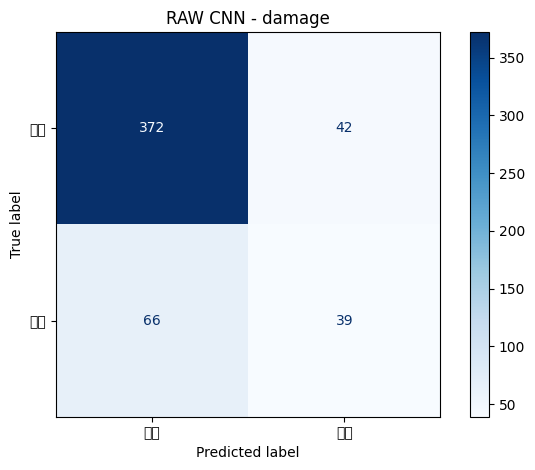


[OPENCV]
              precision    recall  f1-score   support

          정상     0.8714    0.8841    0.8777       414
          손상     0.5152    0.4857    0.5000       105

    accuracy                         0.8035       519
   macro avg     0.6933    0.6849    0.6888       519
weighted avg     0.7993    0.8035    0.8013       519



/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 49552 (\N{HANGUL SYLLABLE SON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49552 (\N{HANGUL SYLLABLE SON}) missing from font(s) DejaVu Sans.
  fig.c

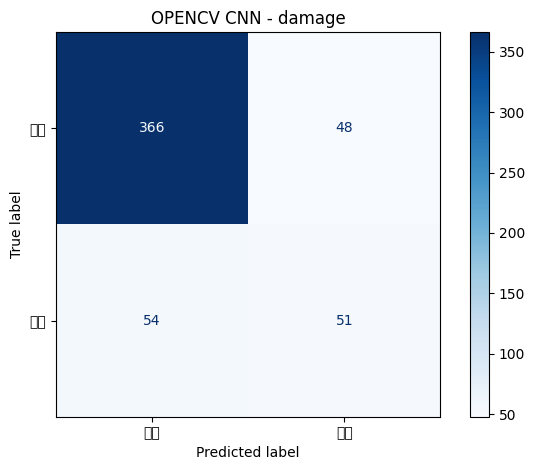


TASK: cover

[RAW]
              precision    recall  f1-score   support

       겹침 없음     0.9212    0.8833    0.9019       437
          겹침     0.4900    0.5976    0.5385        82

    accuracy                         0.8382       519
   macro avg     0.7056    0.7404    0.7202       519
weighted avg     0.8531    0.8382    0.8445       519



/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 44217 (\N{HANGUL SYLLABLE GYEOB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 52840 (\N{HANGUL SYLLABLE CIM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 50630 (\N{HANGUL SYLLABLE EOBS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 51020 (\N{HANGUL SYLLABLE EUM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44217 (\N{HANGUL SYLLABLE GYEOB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52840 (\N{HANGUL SYLLABLE CIM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python

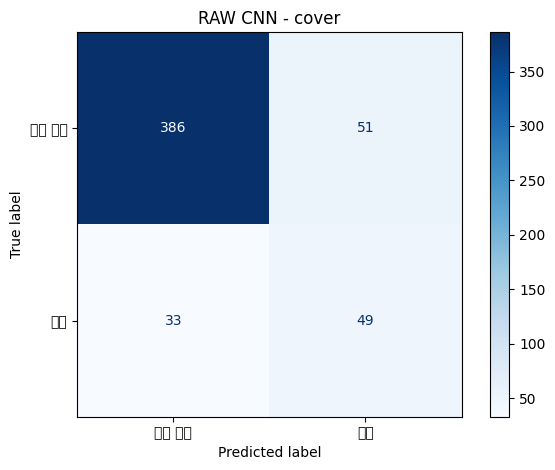


[OPENCV]
              precision    recall  f1-score   support

       겹침 없음     0.9225    0.8993    0.9108       437
          겹침     0.5269    0.5976    0.5600        82

    accuracy                         0.8516       519
   macro avg     0.7247    0.7484    0.7354       519
weighted avg     0.8600    0.8516    0.8554       519



/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 44217 (\N{HANGUL SYLLABLE GYEOB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 52840 (\N{HANGUL SYLLABLE CIM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 50630 (\N{HANGUL SYLLABLE EOBS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 51020 (\N{HANGUL SYLLABLE EUM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44217 (\N{HANGUL SYLLABLE GYEOB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52840 (\N{HANGUL SYLLABLE CIM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python

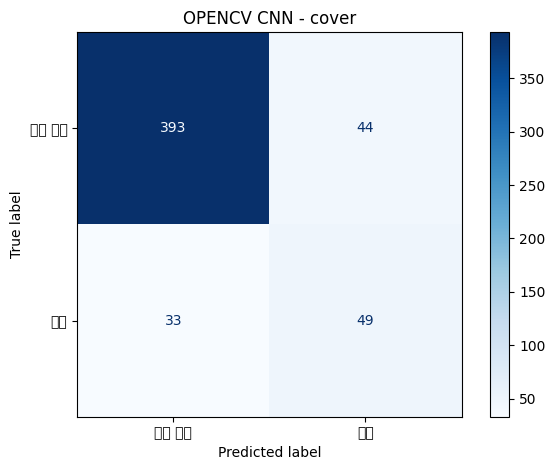


TASK: dirtiness

[RAW]
              precision    recall  f1-score   support

       오염 없음     0.8884    0.9673    0.9262       214
          오염     0.9755    0.9148    0.9442       305

    accuracy                         0.9364       519
   macro avg     0.9320    0.9410    0.9352       519
weighted avg     0.9396    0.9364    0.9367       519



/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 50724 (\N{HANGUL SYLLABLE O}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 50684 (\N{HANGUL SYLLABLE YEOM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 50630 (\N{HANGUL SYLLABLE EOBS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 51020 (\N{HANGUL SYLLABLE EUM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50724 (\N{HANGUL SYLLABLE O}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50684 (\N{HANGUL SYLLABLE YEOM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/d

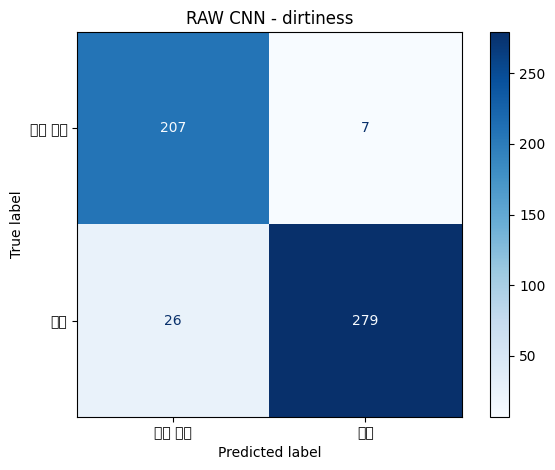


[OPENCV]
              precision    recall  f1-score   support

       오염 없음     0.8973    0.9393    0.9178       214
          오염     0.9559    0.9246    0.9400       305

    accuracy                         0.9306       519
   macro avg     0.9266    0.9319    0.9289       519
weighted avg     0.9318    0.9306    0.9308       519



/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 50724 (\N{HANGUL SYLLABLE O}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 50684 (\N{HANGUL SYLLABLE YEOM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 50630 (\N{HANGUL SYLLABLE EOBS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 51020 (\N{HANGUL SYLLABLE EUM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50724 (\N{HANGUL SYLLABLE O}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50684 (\N{HANGUL SYLLABLE YEOM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/d

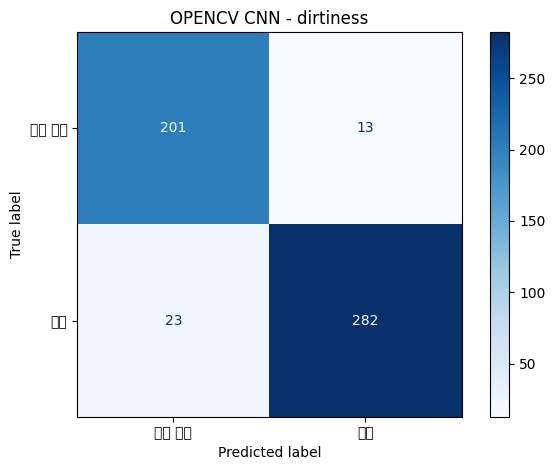


TASK: transparency

[RAW]
              precision    recall  f1-score   support

         불투명     0.9675    0.9789    0.9732       426
          투명     0.8977    0.8495    0.8729        93

    accuracy                         0.9557       519
   macro avg     0.9326    0.9142    0.9230       519
weighted avg     0.9550    0.9557    0.9552       519



/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 48520 (\N{HANGUL SYLLABLE BUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 53804 (\N{HANGUL SYLLABLE TU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 47749 (\N{HANGUL SYLLABLE MYEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48520 (\N{HANGUL SYLLABLE BUL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 53804 (\N{HANGUL SYLLABLE TU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47749 (\N{HANGUL SYLLABLE MYEONG}) missing from font(s) DejaVu Sans.
  fig.can

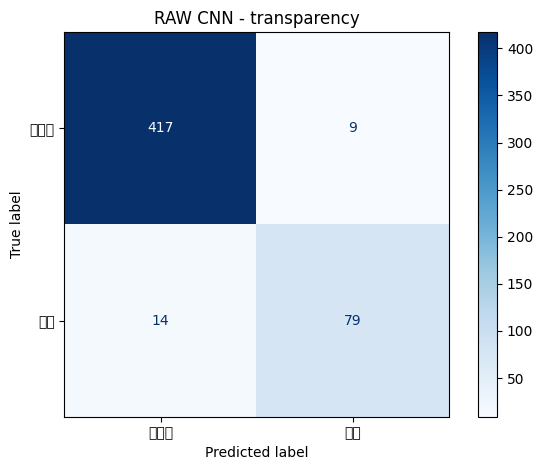


[OPENCV]
              precision    recall  f1-score   support

         불투명     0.9718    0.9718    0.9718       426
          투명     0.8710    0.8710    0.8710        93

    accuracy                         0.9538       519
   macro avg     0.9214    0.9214    0.9214       519
weighted avg     0.9538    0.9538    0.9538       519



/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 48520 (\N{HANGUL SYLLABLE BUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 53804 (\N{HANGUL SYLLABLE TU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_867/3848822165.py:128: UserWarning: Glyph 47749 (\N{HANGUL SYLLABLE MYEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48520 (\N{HANGUL SYLLABLE BUL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 53804 (\N{HANGUL SYLLABLE TU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47749 (\N{HANGUL SYLLABLE MYEONG}) missing from font(s) DejaVu Sans.
  fig.can

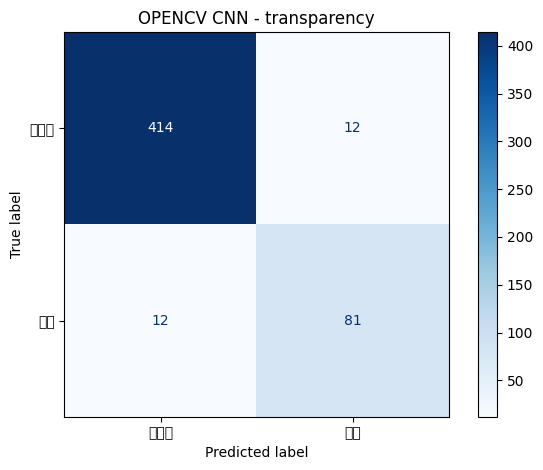

damage          | 서로 다른 예측: 60개
cover           | 서로 다른 예측: 53개
dirtiness       | 서로 다른 예측: 15개
transparency    | 서로 다른 예측: 15개

분석 완료!


In [38]:

# =====================================================
# 통합 Validation 오류 분석
# YOLO + RAW CNN vs OpenCV CNN
# =====================================================

import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    f1_score
)

SAVE_ROOT = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "AI개론/261110스터디/multiclass_yolo26n"
)

PRED_PATH = (
    SAVE_ROOT
    / "integrated_validation"
    / "matched_predictions.csv"
)

assert PRED_PATH.exists(), PRED_PATH

df = pd.read_csv(PRED_PATH)

HEAD_LABELS = {
    "damage": ["정상", "손상"],
    "cover": ["겹침 없음", "겹침"],
    "dirtiness": ["오염 없음", "오염"],
    "transparency": ["불투명", "투명"]
}

print("분석 ROI:", len(df))

# -----------------------------------------
# 1. YOLO와 CNN 클래스 예측 비교
# -----------------------------------------

gt = df["gt_class_id"]

yolo_correct = (
    df["yolo_class"] == gt
)

print("\n===== 클래스 예측 정확도 =====")

for name, column in [
    ("YOLO", "yolo_class"),
    ("RAW CNN", "raw_class_id"),
    ("OpenCV CNN", "opencv_class_id")
]:
    accuracy = (df[column] == gt).mean()
    print(f"{name:12s}: {accuracy:.2%}")

# CNN이 YOLO의 오분류를 수정한 경우
for variant in ["raw", "opencv"]:
    cnn_correct = (
        df[f"{variant}_class_id"] == gt
    )

    rescued = (
        (~yolo_correct) & cnn_correct
    ).sum()

    worsened = (
        yolo_correct & (~cnn_correct)
    ).sum()

    print(f"\n{variant.upper()} CNN")
    print("YOLO 오분류 수정:", rescued)
    print("YOLO 정분류를 오분류:", worsened)

# -----------------------------------------
# 2. 속성별 Confusion Matrix
# -----------------------------------------

for task, labels in HEAD_LABELS.items():

    y_true = df[f"gt_{task}"].astype(int)

    print(f"\n{'=' * 55}")
    print("TASK:", task)
    print(f"{'=' * 55}")

    for variant in ["raw", "opencv"]:

        y_pred = df[
            f"{variant}_{task}"
        ].astype(int)

        print(f"\n[{variant.upper()}]")

        print(classification_report(
            y_true,
            y_pred,
            labels=[0, 1],
            target_names=labels,
            digits=4,
            zero_division=0
        ))

        cm = confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1]
        )

        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=labels
        )

        disp.plot(
            values_format="d",
            cmap="Blues"
        )

        plt.title(
            f"{variant.upper()} CNN - {task}"
        )

        plt.tight_layout()
        plt.show()

# -----------------------------------------
# 3. 모델 간 예측이 다른 객체 확인
# -----------------------------------------

for task in HEAD_LABELS:

    disagreement = df[
        df[f"raw_{task}"] !=
        df[f"opencv_{task}"]
    ]

    print(
        f"{task:15s} | "
        f"서로 다른 예측: {len(disagreement)}개"
    )

print("\n분석 완료!")


# 태스크별로 CNN을 선택한 Hybrid 모델

In [39]:

# ============================================================
# Hybrid Multi-task Pipeline Validation
# YOLO 클래스 + RAW/OpenCV CNN 속성 선택
# ============================================================

import pandas as pd
from pathlib import Path
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    confusion_matrix
)
from IPython.display import display

SAVE_ROOT = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "AI개론/261110스터디/multiclass_yolo26n"
)

INPUT_PATH = (
    SAVE_ROOT / "integrated_validation"
    / "matched_predictions.csv"
)

OUTPUT_DIR = SAVE_ROOT / "hybrid_validation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(INPUT_PATH)

assert len(df) == 519

HEAD_DIMS = {
    "class_id": 5,
    "damage": 2,
    "dirtiness": 2,
    "cover": 2,
    "transparency": 2
}

# Hybrid 헤드별 모델 선택
HYBRID_SOURCES = {
    "class_id": "yolo",
    "damage": "opencv",
    "dirtiness": "raw",
    "cover": "opencv",
    "transparency": "raw"
}

# 기존 모델과 Hybrid 비교
VARIANTS = {
    "RAW CNN": {
        h: f"raw_{h}" for h in HEAD_DIMS
    },
    "OpenCV CNN": {
        h: f"opencv_{h}" for h in HEAD_DIMS
    },
    "Hybrid": {
        h: (
            "yolo_class"
            if source == "yolo"
            else f"{source}_{h}"
        )
        for h, source in HYBRID_SOURCES.items()
    }
}

records = []
prediction_df = df.copy()

for variant, mapping in VARIANTS.items():

    for head, n_classes in HEAD_DIMS.items():
        gt_col = f"gt_{head}"
        pred_col = mapping[head]

        y_true = df[gt_col].astype(int)
        y_pred = df[pred_col].astype(int)

        accuracy = accuracy_score(
            y_true, y_pred
        )

        macro_f1 = f1_score(
            y_true,
            y_pred,
            labels=list(range(n_classes)),
            average="macro",
            zero_division=0
        )

        records.append({
            "Model": variant,
            "Task": head,
            "Accuracy": accuracy,
            "Macro-F1": macro_f1,
            "Prediction Source": pred_col
        })

        prediction_df[
            f"{variant.replace(' ', '_')}_{head}"
        ] = y_pred

df_metrics = pd.DataFrame(records)

print("===== 태스크별 Macro-F1 =====")

display(
    df_metrics.pivot(
        index="Task",
        columns="Model",
        values="Macro-F1"
    ).round(4)
)

# ==========================================
# 평균 점수
# ==========================================

df_summary = (
    df_metrics.groupby("Model")
    .agg(
        Mean_Macro_F1=("Macro-F1", "mean"),
        Mean_Accuracy=("Accuracy", "mean")
    )
    .sort_values(
        "Mean_Macro_F1",
        ascending=False
    )
)

print("\n===== 모델별 평균 =====")
display(df_summary.round(4))

# ==========================================
# 손상 / 겹침 이진 분류 오류
# ==========================================

for head in ["damage", "cover"]:

    source = HYBRID_SOURCES[head]

    y_true = df[f"gt_{head}"].astype(int)
    y_pred = df[f"{source}_{head}"].astype(int)

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    print(f"\n===== Hybrid {head} =====")
    print("TP:", tp)
    print("FP:", fp)
    print("FN:", fn)
    print("TN:", tn)
    print(
        "Positive Recall:",
        f"{tp / (tp + fn):.2%}"
        if tp + fn else "N/A"
    )

# ==========================================
# 결과 저장
# ==========================================

df_metrics.to_csv(
    OUTPUT_DIR / "hybrid_task_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

df_summary.to_csv(
    OUTPUT_DIR / "hybrid_summary.csv",
    encoding="utf-8-sig"
)

prediction_df.to_csv(
    OUTPUT_DIR / "hybrid_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n===== 완료 =====")
print("Validation 매칭 ROI:", len(df))
print("결과 저장:", OUTPUT_DIR)


===== 태스크별 Macro-F1 =====


Model,Hybrid,OpenCV CNN,RAW CNN
Task,,,
class_id,0.9522,0.9298,0.9455
cover,0.7354,0.7354,0.7202
damage,0.6888,0.6888,0.6463
dirtiness,0.9352,0.9289,0.9352
transparency,0.9230,0.9214,0.9230



===== 모델별 평균 =====


,Mean_Macro_F1,Mean_Accuracy
Model,,
Hybrid,0.8469,0.9013
OpenCV CNN,0.8409,0.8956
RAW CNN,0.8340,0.8952



===== Hybrid damage =====
TP: 51
FP: 48
FN: 54
TN: 366
Positive Recall: 48.57%

===== Hybrid cover =====
TP: 49
FP: 44
FN: 33
TN: 393
Positive Recall: 59.76%

===== 완료 =====
Validation 매칭 ROI: 519
결과 저장: /content/drive/MyDrive/Colab Notebooks/AI개론/261110스터디/multiclass_yolo26n/hybrid_validation


# Hybrid End-to-End Test

In [42]:
# ============================================================
# CELL 1. Hybrid End-to-End TEST
# RAW YOLO26n + RAW/OpenCV Multi-task ResNet18
# ============================================================

import cv2
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from torchvision import transforms
from torchvision.models import resnet18
from ultralytics import YOLO
from sklearn.metrics import f1_score, accuracy_score
from IPython.display import display

# ============================================================
# 1. 환경 설정
# ============================================================

SEED = 42
CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.50
BATCH_SIZE = 64

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

ROOT = Path("/content/multiclass_yolo26n")
RAW_ROOT = ROOT / "dataset_raw"

SAVE_ROOT = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "AI개론/261110스터디/multiclass_yolo26n"
)

MODEL_DIR = SAVE_ROOT / "models"
OUTPUT_DIR = SAVE_ROOT / "hybrid_test"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = {
    0: "styrofoam",
    1: "vinyl",
    2: "brown_glass",
    3: "green_glass",
    4: "clear_glass"
}

CLASS_MAP = {
    ("스티로폼", "스티로폼"): 0,
    ("비닐", "비닐"): 1,
    ("유리병", "갈색"): 2,
    ("유리병", "녹색"): 3,
    ("유리병", "투명"): 4
}

HEAD_DIMS = {
    "class_id": 5,
    "damage": 2,
    "dirtiness": 2,
    "cover": 2,
    "transparency": 2
}

ATTRIBUTE_HEADS = [
    "damage",
    "dirtiness",
    "cover",
    "transparency"
]

# Validation에서 확정한 Hybrid 구성
HYBRID_SOURCES = {
    "damage": "opencv",
    "dirtiness": "raw",
    "cover": "opencv",
    "transparency": "raw"
}

# ============================================================
# 2. Multi-task CNN 구조
# ============================================================

class MultiTaskResNet18(nn.Module):

    def __init__(self):
        super().__init__()

        self.backbone = resnet18(weights=None)
        feature_dim = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()

        self.heads = nn.ModuleDict({
            name: nn.Sequential(
                nn.Dropout(0.2),
                nn.Linear(feature_dim, num_classes)
            )
            for name, num_classes in HEAD_DIMS.items()
        })

    def forward(self, x):
        features = self.backbone(x)

        return {
            name: head(features)
            for name, head in self.heads.items()
        }


def load_cnn(variant):
    path = (
        MODEL_DIR /
        f"resnet18_multitask_{variant}_best.pt"
    )

    assert path.exists(), path

    # UnpicklingError 해결을 위해 weights_only=False로 로드합니다.
    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    model = MultiTaskResNet18()
    model.load_state_dict(
        checkpoint["model_state"]
    )

    model = model.to(DEVICE).eval()

    print(
        f"CNN {variant}: Best Epoch "
        f"{checkpoint['epoch']}"
    )

    return model


# ============================================================
# 3. 모델 로드
# ============================================================

YOLO_PATH = MODEL_DIR / "yolo26n_raw_best.pt"

assert YOLO_PATH.exists(), YOLO_PATH

yolo = YOLO(str(YOLO_PATH))

cnn_raw = load_cnn("raw")
cnn_cv = load_cnn("opencv")

# ============================================================
# 4. ROI 전처리
# 기존 학습 때 사용한 함수와 동일
# ============================================================

def letterbox_roi(image, size=224):

    h, w = image.shape[:2]
    scale = min(size / w, size / h)

    nw = max(1, round(w * scale))
    nh = max(1, round(h * scale))

    resized = cv2.resize(
        image, (nw, nh),
        interpolation=(
            cv2.INTER_AREA
            if scale < 1 else cv2.INTER_LINEAR
        )
    )

    canvas = np.full(
        (size, size, 3), 114,
        dtype=np.uint8
    )

    x = (size - nw) // 2
    y = (size - nh) // 2

    canvas[y:y+nh, x:x+nw] = resized

    return canvas


def preprocess_roi(image):

    lab = cv2.cvtColor(
        image, cv2.COLOR_BGR2LAB
    )

    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=1.5,
        tileGridSize=(8, 8)
    )

    enhanced_l = clahe.apply(l)

    l = cv2.addWeighted(
        l, 0.65,
        enhanced_l, 0.35,
        0
    )

    enhanced = cv2.cvtColor(
        cv2.merge([l, a, b]),
        cv2.COLOR_LAB2BGR
    )

    return cv2.bilateralFilter(
        enhanced, 5, 30, 30
    )


normalize = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ============================================================
# 5. 속성 정답 인코딩
# ============================================================

def encode_attributes(obj):

    damage = str(obj.get("DAMAGE", "")).strip()
    dirt = str(obj.get("DIRTINESS", "")).strip()
    cover = str(obj.get("COVER", "")).strip()
    trans = str(obj.get("TRANSPARENCY", "")).strip()

    assert damage in {
        "원형", "파손", "찢어짐", "찌그러짐"
    }, damage

    assert dirt in {
        "오염없음",
        "이물질(외부)",
        "이물질(내부)",
        "이물질(전체)"
    }, dirt

    assert cover in {"없음", "겹침"}, cover
    assert trans in {"불투명", "투명"}, trans

    return {
        "damage": int(damage != "원형"),
        "dirtiness": int(dirt != "오염없음"),
        "cover": int(cover == "겹침"),
        "transparency": int(trans == "투명")
    }


# ============================================================
# 6. IoU와 클래스 일치 기반 매칭
# ============================================================

def calculate_iou(a, b):

    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    inter = (
        max(0, x2-x1) *
        max(0, y2-y1)
    )

    area_a = (
        max(0, a[2]-a[0]) *
        max(0, a[3]-a[1])
    )

    area_b = (
        max(0, b[2]-b[0]) *
        max(0, b[3]-b[1])
    )

    union = area_a + area_b - inter

    return inter / union if union > 0 else 0.0


def match_detections(preds, gts):

    # 높은 Confidence 순서로 1:1 매칭
    order = sorted(
        range(len(preds)),
        key=lambda i: -preds[i]["confidence"]
    )

    matched_gt = set()
    matches = {}

    for pi in order:

        pred = preds[pi]

        best_iou = IOU_THRESHOLD
        best_gi = None

        for gi, gt in enumerate(gts):

            if gi in matched_gt:
                continue

            # 클래스도 일치해야 TP 인정
            if pred["class_id"] != gt["class_id"]:
                continue

            iou = calculate_iou(
                pred["box"], gt["box"]
            )

            if iou >= best_iou:
                best_iou = iou
                best_gi = gi

        if best_gi is not None:
            matched_gt.add(best_gi)
            matches[pi] = (best_gi, best_iou)

    return matches


# ============================================================
# 7. Test Manifest
# ============================================================

manifest = pd.read_csv(
    SAVE_ROOT / "split_manifest.csv"
)

test_df = manifest[
    manifest["split"] == "test"
].reset_index(drop=True)

assert len(test_df) == 300

# ============================================================
# 8. YOLO 추론 + 실제 예측 박스 ROI 생성
# ============================================================

prediction_rows = []
ground_truth_rows = []

raw_crops = []
cv_crops = []

for row in tqdm(
    test_df.itertuples(index=False),
    total=len(test_df),
    desc="Hybrid Test YOLO → ROI",
    unit="image"
):

    stem = (
        f"{row.class_name}__"
        f"{Path(row.image_path).stem}"
    )

    img_path = (
        RAW_ROOT / "images" / "test"
        / f"{stem}.jpg"
    )

    lbl_path = (
        RAW_ROOT / "labels" / "test"
        / f"{stem}.txt"
    )

    image = cv2.imread(str(img_path))

    if image is None:
        raise FileNotFoundError(img_path)

    H, W = image.shape[:2]

    with open(row.label_path, encoding="utf-8-sig") as f:
        json_data = json.load(f)

    if json_data["IMAGE_INFO"]["FILE_NAME"] != Path(row.image_path).name:
        raise ValueError(f"JSON/이미지 불일치: {stem}")

    objects = json_data.get("ANNOTATION_INFO", [])
    lines = lbl_path.read_text().splitlines()

    if len(objects) != len(lines):
        raise ValueError(f"GT 개수 불일치: {stem}")

    gts = []

    for gi, (obj, line) in enumerate(
        zip(objects, lines)
    ):
        cls, cx, cy, bw, bh = map(
            float, line.split()
        )

        cls = int(cls)

        expected_cls = CLASS_MAP.get((
            obj.get("CLASS"),
            obj.get("DETAILS")
        ))

        if cls != expected_cls:
            raise ValueError(
                f"GT 클래스 불일치: {stem}/{gi}"
            )

        box = [
            (cx-bw/2)*W,
            (cy-bh/2)*H,
            (cx+bw/2)*W,
            (cy+bh/2)*H
        ]

        attrs = encode_attributes(obj)

        gts.append({
            "class_id": cls,
            "box": box,
            "attrs": attrs
        })

        gt_record = {
            "image": img_path.name,
            "gt_idx": gi,
            "class_id": cls,
            "matched": False
        }

        gt_record.update(attrs)
        ground_truth_rows.append(gt_record)

    # YOLO 탐지
    result = yolo.predict(
        source=image,
        conf=CONF_THRESHOLD,
        imgsz=640,
        device=0 if DEVICE.type == "cuda" else "cpu",
        verbose=False
    )[0]

    preds = []

    for box, cls, conf in zip(
        result.boxes.xyxy.cpu().numpy(),
        result.boxes.cls.cpu().numpy(),
        result.boxes.conf.cpu().numpy()
    ):
        preds.append({
            "box": box.tolist(),
            "class_id": int(cls),
            "confidence": float(conf)
        })

    matches = match_detections(preds, gts)

    # 이미지별 GT 행의 시작 위치
    gt_start = len(ground_truth_rows) - len(gts)

    for pi, (pred) in enumerate(preds):

        matched = pi in matches

        gi = matches[pi][0] if matched else -1
        iou = matches[pi][1] if matched else 0.0

        if matched:
            ground_truth_rows[
                gt_start + gi
            ]["matched"] = True

        x1, y1, x2, y2 = pred["box"]

        # CNN 학습 때와 동일하게 8% margin
        margin = 0.08 * max(
            x2-x1, y2-y1
        )

        rx1 = max(0, int(x1-margin))
        ry1 = max(0, int(y1-margin))
        rx2 = min(W, int(np.ceil(x2+margin)))
        ry2 = min(H, int(np.ceil(y2+margin)))

        if rx2 <= rx1 or ry2 <= ry1:
            raise ValueError(
                f"빈 예측 ROI: {stem}/{pi}"
            )

        crop = image[ry1:ry2, rx1:rx2]

        raw_roi = letterbox_roi(crop)
        cv_roi = preprocess_roi(raw_roi)

        raw_crops.append(raw_roi)
        cv_crops.append(cv_roi)

        pred_record = {
            "image": img_path.name,
            "pred_idx": pi,
            "class_id": pred["class_id"],
            "confidence": pred["confidence"],
            "matched": matched,
            "gt_idx": gi,
            "iou": iou,
            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2
        }

        if matched:
            for head in ATTRIBUTE_HEADS:
                pred_record[f"gt_{head}"] = (
                    gts[gi]["attrs"][head]
                )

        prediction_rows.append(pred_record)


# ============================================================
# 9. CNN 배치 추론
# ============================================================

@torch.inference_mode()
def predict_cnn(model, crops):

    model.eval()

    predictions = {
        h: [] for h in ATTRIBUTE_HEADS
    }

    for start in tqdm(
        range(0, len(crops), BATCH_SIZE),
        desc="CNN Batch 추론",
        unit="batch"
    ):

        batch_crops = crops[
            start:start+BATCH_SIZE
        ]

        tensors = [
            normalize(
                Image.fromarray(
                    cv2.cvtColor(
                        crop, cv2.COLOR_BGR2RGB
                    )
                )
            )
            for crop in batch_crops
        ]

        batch = torch.stack(
            tensors
        ).to(DEVICE)

        outputs = model(batch)

        for head in ATTRIBUTE_HEADS:
            predictions[head].extend(
                outputs[head]
                .argmax(1)
                .cpu()
                .tolist()
            )

    return predictions


raw_outputs = predict_cnn(
    cnn_raw, raw_crops
)

cv_outputs = predict_cnn(
    cnn_cv, cv_crops
)

df_pred = pd.DataFrame(prediction_rows)
df_gt = pd.DataFrame(ground_truth_rows)

assert len(df_pred) == len(raw_crops) == len(cv_crops)

for head in ATTRIBUTE_HEADS:

    source = HYBRID_SOURCES[head]

    values = (
        raw_outputs[head]
        if source == "raw"
        else cv_outputs[head]
    )

    df_pred[head] = values

# ============================================================
# 10. End-to-End 탐지 평가
# ============================================================

TP = int(df_pred["matched"].sum())
FP = len(df_pred) - TP
FN = len(df_gt) - TP

precision = TP / (TP + FP) if TP + FP else 0.0
recall = TP / (TP + FN) if TP + FN else 0.0
f1 = (
    2*precision*recall/(precision+recall)
    if precision+recall else 0.0
)

df_detection = pd.DataFrame([{
    "GT": len(df_gt),
    "Predictions": len(df_pred),
    "TP": TP,
    "FP": FP,
    "FN": FN,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "IoU": IOU_THRESHOLD,
    "Confidence": CONF_THRESHOLD
}])

print("\n===== End-to-End 객체 탐지 =====")
display(df_detection)

# 클래스별 고정 Confidence 탐지 성능
class_records = []

for cls_id, cls_name in CLASS_NAMES.items():

    gt_count = int(
        (df_gt["class_id"] == cls_id).sum()
    )

    pred_mask = df_pred["class_id"] == cls_id

    tp = int(
        (pred_mask & df_pred["matched"]).sum()
    )
    fp = int(pred_mask.sum()) - tp
    fn = gt_count - tp

    p = tp/(tp+fp) if tp+fp else 0
    r = tp/(tp+fn) if tp+fn else 0

    class_records.append({
        "Class": cls_name,
        "GT": gt_count,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": p,
        "Recall": r,
        "F1": 2*p*r/(p+r) if p+r else 0
    })

df_classes = pd.DataFrame(class_records)

print("\n===== 클래스별 End-to-End 탐지 =====")
display(df_classes)

# ============================================================
# 11. 속성별 End-to-End 평가
#
# GT positive 중 올바르게 예측한 객체 = TP
# GT positive인데 놓치거나 0 예측 = FN
# 예측 positive인데 GT가 없거나 0 = FP
# ============================================================

matched_df = df_pred[
    df_pred["matched"]
].copy()

attr_records = []

for head in ATTRIBUTE_HEADS:

    # 모든 GT 중 positive의 수
    gt_positive = int(df_gt[head].sum())

    pred_positive = int(df_pred[head].sum())

    tp = int((
        (matched_df[head] == 1) &
        (matched_df[f"gt_{head}"] == 1)
    ).sum())

    fp = pred_positive - tp
    fn = gt_positive - tp

    p = tp/(tp+fp) if tp+fp else 0
    r = tp/(tp+fn) if tp+fn else 0

    attr_records.append({
        "Task": head,
        "GT Positive": gt_positive,
        "Pred Positive": pred_positive,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": p,
        "Recall": r,
        "F1": 2*p*r/(p+r) if p+r else 0
    })

df_attributes = pd.DataFrame(attr_records)

print("\n===== End-to-End 속성 Positive 성능 =====")
display(df_attributes)

# ============================================================
# 12. 조건부 속성 Macro-F1
# 올바른 탐지 위치·클래스에서만 평가
# ============================================================

conditional_records = []

for head in ATTRIBUTE_HEADS:

    y_true = matched_df[f"gt_{head}"].astype(int)
    y_pred = matched_df[head].astype(int)

    conditional_records.append({
        "Task": head,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro-F1": f1_score(
            y_true,
            y_pred,
            labels=[0, 1],
            average="macro",
            zero_division=0
        )
    })

df_conditional = pd.DataFrame(
    conditional_records
)

print("\n===== 성공적으로 탐지된 객체의 CNN 성능 =====")
display(df_conditional)

# 모든 속성을 정확히 맞힌 객체 수
all_attrs_correct = np.ones(
    len(matched_df), dtype=bool
)

for head in ATTRIBUTE_HEADS:
    all_attrs_correct &= (
        matched_df[head].to_numpy() ==
        matched_df[f"gt_{head}"].to_numpy()
    )

all_correct = int(all_attrs_correct.sum())

print("\n===== 완전 일치 객체 =====")
print("탐지 + 4개 속성 모두 정답:", all_correct)
print(
    "전체 GT 기준 성공 비율:",
    f"{all_correct / len(df_gt):.2%}"
)

# ============================================================
# 13. Google Drive 저장
# ============================================================

df_detection.to_csv(
    OUTPUT_DIR / "detection_summary.csv",
    index=False, encoding="utf-8-sig"
)

df_classes.to_csv(
    OUTPUT_DIR / "class_detection_metrics.csv",
    index=False, encoding="utf-8-sig"
)

df_attributes.to_csv(
    OUTPUT_DIR / "attribute_end_to_end.csv",
    index=False, encoding="utf-8-sig"
)

df_conditional.to_csv(
    OUTPUT_DIR / "attribute_conditional.csv",
    index=False, encoding="utf-8-sig"
)

df_pred.to_csv(
    OUTPUT_DIR / "predictions.csv",
    index=False, encoding="utf-8-sig"
)

df_gt.to_csv(
    OUTPUT_DIR / "ground_truth.csv",
    index=False, encoding="utf-8-sig"
)

print("\n===== HYBRID TEST 완료 =====")
print("저장 경로:", OUTPUT_DIR)

CNN raw: Best Epoch 8
CNN opencv: Best Epoch 3


Hybrid Test YOLO → ROI:   0%|          | 0/300 [00:00<?, ?image/s]

CNN Batch 추론:   0%|          | 0/12 [00:00<?, ?batch/s]

CNN Batch 추론:   0%|          | 0/12 [00:00<?, ?batch/s]


===== End-to-End 객체 탐지 =====


,GT,Predictions,TP,FP,FN,Precision,Recall,F1,IoU,Confidence
0,622,754,434,320,188,0.575597,0.697749,0.630814,0.5,0.25


... (3 outputs left out)

,Task,GT Positive,Pred Positive,TP,FP,FN,Precision,Recall,F1
0,damage,166,169,54,115,112,0.319527,0.325301,0.322388
1,dirtiness,402,476,284,192,118,0.596639,0.706468,0.646925
2,cover,139,197,44,153,95,0.223350,0.316547,0.261905
3,transparency,133,161,94,67,39,0.583851,0.706767,0.639456



===== 성공적으로 탐지된 객체의 CNN 성능 =====


,Task,Accuracy,Macro-F1
0,damage,0.822581,0.735523
1,dirtiness,0.877880,0.850039
2,cover,0.829493,0.719197
3,transparency,0.949309,0.930902



===== 완전 일치 객체 =====
탐지 + 4개 속성 모두 정답: 269
전체 GT 기준 성공 비율: 43.25%

===== HYBRID TEST 완료 =====
저장 경로: /content/drive/MyDrive/Colab Notebooks/AI개론/261110스터디/multiclass_yolo26n/hybrid_test


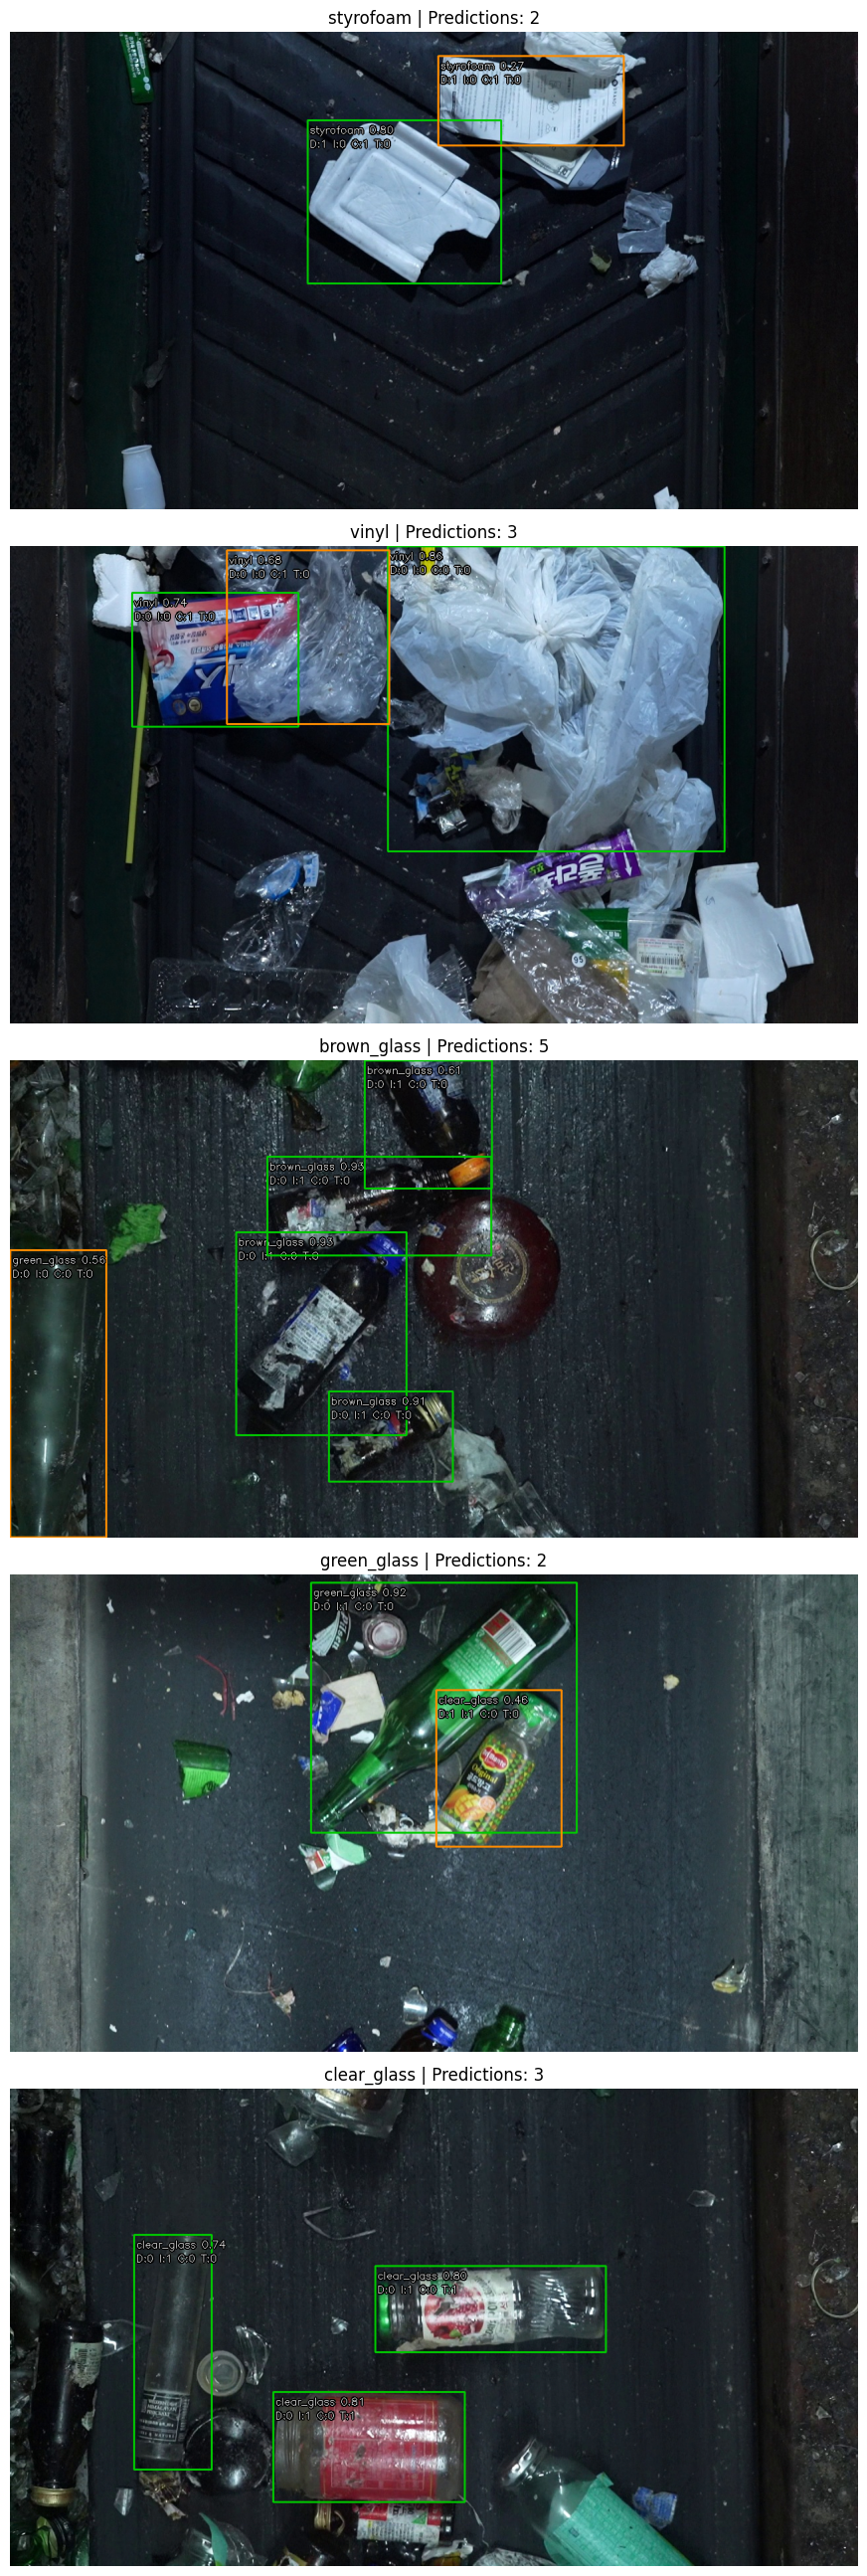


===== 속성 코드 =====
D = Damage (1: 손상)
I = Dirtiness (1: 오염)
C = Cover (1: 겹침)
T = Transparency (1: 투명)

초록색: 정답과 위치·클래스 매칭
주황색: 매칭되지 않은 예측
시각화 저장: /content/drive/MyDrive/Colab Notebooks/AI개론/261110스터디/multiclass_yolo26n/hybrid_test/visualizations


In [43]:

# ============================================================
# CELL 2. Hybrid Test Prediction Visualization
# ============================================================

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

ROOT = Path("/content/multiclass_yolo26n")
RAW_ROOT = ROOT / "dataset_raw"

SAVE_ROOT = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "AI개론/261110스터디/multiclass_yolo26n"
)

RESULT_DIR = SAVE_ROOT / "hybrid_test"
VIS_DIR = RESULT_DIR / "visualizations"

VIS_DIR.mkdir(parents=True, exist_ok=True)

df_pred = pd.read_csv(
    RESULT_DIR / "predictions.csv"
)

manifest = pd.read_csv(
    SAVE_ROOT / "split_manifest.csv"
)

test_df = manifest[
    manifest["split"] == "test"
].copy()

CLASS_NAMES = {
    0: "styrofoam",
    1: "vinyl",
    2: "brown_glass",
    3: "green_glass",
    4: "clear_glass"
}

def draw_hybrid_predictions(image, predictions):

    canvas = image.copy()
    H, W = canvas.shape[:2]

    for row in predictions.itertuples(index=False):

        x1 = max(0, int(row.x1))
        y1 = max(0, int(row.y1))
        x2 = min(W-1, int(row.x2))
        y2 = min(H-1, int(row.y2))

        cls_name = CLASS_NAMES[int(row.class_id)]

        # 초록: GT에 매칭된 검출 / 주황: 미매칭 검출
        color = (
            (0, 200, 0)
            if row.matched
            else (0, 140, 255)
        )

        cv2.rectangle(
            canvas,
            (x1, y1),
            (x2, y2),
            color,
            2
        )

        class_text = (
            f"{cls_name} {row.confidence:.2f}"
        )

        attr_text = (
            f"D:{int(row.damage)} "
            f"I:{int(row.dirtiness)} "
            f"C:{int(row.cover)} "
            f"T:{int(row.transparency)}"
        )

        for line_idx, text in enumerate([
            class_text, attr_text
        ]):

            ty = min(
                H - 8,
                max(18, y1 + 20 + 21*line_idx)
            )

            cv2.putText(
                canvas, text,
                (x1 + 3, ty),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.52,
                (0, 0, 0),
                3
            )

            cv2.putText(
                canvas, text,
                (x1 + 3, ty),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.52,
                (255, 255, 255),
                1
            )

    return canvas


# 클래스별 Test 이미지 1장씩 선택
samples = (
    test_df.groupby("class_name")
    .sample(n=1, random_state=42)
    .sort_values("class_id")
)

fig, axes = plt.subplots(
    5, 1, figsize=(15, 26)
)

for ax, row in zip(
    axes, samples.itertuples(index=False)
):

    name = (
        f"{row.class_name}__"
        f"{Path(row.image_path).stem}.jpg"
    )

    image_path = (
        RAW_ROOT / "images" / "test" / name
    )

    image = cv2.imread(str(image_path))

    if image is None:
        raise FileNotFoundError(image_path)

    predictions = df_pred[
        df_pred["image"] == name
    ]

    annotated = draw_hybrid_predictions(
        image, predictions
    )

    output_path = VIS_DIR / name

    cv2.imwrite(
        str(output_path),
        annotated
    )

    ax.imshow(
        cv2.cvtColor(
            annotated,
            cv2.COLOR_BGR2RGB
        )
    )

    ax.set_title(
        f"{row.class_name} | "
        f"Predictions: {len(predictions)}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

print("\n===== 속성 코드 =====")
print("D = Damage (1: 손상)")
print("I = Dirtiness (1: 오염)")
print("C = Cover (1: 겹침)")
print("T = Transparency (1: 투명)")

print("\n초록색: 정답과 위치·클래스 매칭")
print("주황색: 매칭되지 않은 예측")
print("시각화 저장:", VIS_DIR)



# 재활용품 다중 클래스 객체 탐지 및 Multi-task Learning 최종 보고서

**프로젝트:** OpenCV + YOLO26n + ResNet18 Multi-task CNN  
**스터디:** ROKEY 11기 2반 · 261110 스터디  
**작성일:** 2026-11-10  
**데이터 출처:** AI Hub 재활용품 분류 및 선별 데이터 (71362)  
**실험 환경:** Google Colab · NVIDIA L4 GPU · PyTorch · Ultralytics YOLO26n

---

## 1. 프로젝트 개요

### 1.1 실험 목적

이번 프로젝트는 재활용품 이미지에서 여러 종류의 객체를 탐지하고, 각 객체의 추가적인 상태까지 예측하는 딥러닝 파이프라인을 구현하는 것을 목표로 한다.

스터디에서 제안된 세 가지 학습 내용을 하나의 프로젝트로 통합하였다.

1. **Multi-class Object Detection:** 여러 종류의 재활용품을 탐지하고 분류한다.
2. **OpenCV 전처리:** 이미지 대비 보정과 노이즈 제거가 모델 성능에 미치는 영향을 분석한다.
3. **CNN 분석:** CNN을 이용하여 객체의 종류 및 추가 속성을 예측한다.

추가적으로 Multi-task Learning을 적용하여 하나의 CNN이 여러 예측 작업을 동시에 수행하도록 구현하였다.

### 1.2 핵심 연구 질문

- OpenCV 전처리는 YOLO 객체 탐지 성능을 개선하는가?
- 다중 클래스 객체 탐지에서 어떤 클래스가 가장 어려운가?
- CNN의 공유 특징 추출기를 이용해 객체의 여러 속성을 동시에 예측할 수 있는가?
- 원본 이미지와 전처리 이미지가 CNN의 속성 분류에 서로 다른 영향을 주는가?
- YOLO와 CNN을 결합했을 때 실제 End-to-End 성능은 어느 정도인가?

### 1.3 최종 구현 범위

| 구분 | 구현 내용 | 상태 |
|---|---|---|
| 데이터 분석 | JSON 구조 및 객체 분포 분석 | 완료 |
| 데이터 전처리 | OpenCV LAB + CLAHE + Bilateral | 완료 |
| 다중 클래스 탐지 | Fine-tuned YOLO26n | 완료 |
| 전처리 비교 | Raw YOLO vs OpenCV YOLO | 완료 |
| CNN 구현 | ResNet18 기반 다중 출력 CNN | 완료 |
| Multi-task Learning | 종류·손상·오염·겹침·투명도 | 완료 |
| Hybrid 모델 | YOLO + Raw CNN + OpenCV CNN | 완료 |
| 최종 평가 | End-to-End Test 300장 | 완료 |
| 시각화 | Bounding Box 및 속성 예측 표시 | 완료 |

---

## 2. 데이터셋 구성

### 2.1 데이터 출처

AI Hub의 재활용품 분류 및 선별 데이터(71362)를 사용하였다.

전체 데이터의 크기가 매우 크기 때문에 원본 데이터셋 중 Validation의 영상추출 이미지 및 라벨링 데이터만 확보하였다.

이번 프로젝트에서는 해당 데이터를 새로운 실험용 데이터셋으로 재구성하였다.

### 2.2 탐지 대상

| Class ID | 클래스 | 설명 |
|---|---|---|
| 0 | styrofoam | 스티로폼 |
| 1 | vinyl | 비닐 |
| 2 | brown_glass | 갈색 유리병 |
| 3 | green_glass | 녹색 유리병 |
| 4 | clear_glass | 투명 유리병 |

총 5개 클래스를 탐지하도록 구성하였다.

### 2.3 데이터 검증 및 중복 제거

처음 검색한 데이터는 이미지와 JSON 파일이 각각 6,027개였다.

그러나 일부 이미지 및 JSON이 상위 폴더와 하위 폴더에 중복 저장되어 있었다.

파일명 기준 중복을 제거하고 실제 이미지와 JSON의 대응 여부를 검증하였다.

| 항목 | 결과 |
|---|---:|
| 최초 검색 이미지 | 6,027 |
| 중복 제거 | 905 |
| 중복 제거 후 이미지 | 5,122 |
| 최종 샘플링 이미지 | 2,000 |
| 최종 어노테이션 객체 | 4,382 |

### 2.4 Train / Validation / Test 구성

각 클래스에서 최대 400장을 추출하였다.

| 클래스 | Train | Val | Test | 합계 |
|---|---:|---:|---:|---:|
| 스티로폼 | 280 | 60 | 60 | 400 |
| 비닐 | 280 | 60 | 60 | 400 |
| 갈색 유리병 | 280 | 60 | 60 | 400 |
| 녹색 유리병 | 280 | 60 | 60 | 400 |
| 투명 유리병 | 280 | 60 | 60 | 400 |
| **합계** | **1,400** | **300** | **300** | **2,000** |

분할 비율은 Train 70%, Validation 15%, Test 15%이다.

영상추출 데이터의 특성을 고려하여 파일명의 촬영 관련 코드 및 프레임 구간을 바탕으로 그룹을 구성하였다.

총 75개의 후보 그룹을 생성하고 그룹 간 중복이 발생하지 않도록 분리하였다.

단, 실제 촬영 영상 ID가 제공된 것은 아니므로 프레임 구간 기반 분리는 완전한 영상 단위 독립성을 보장하지 않는다.

---

## 3. 데이터 라벨링 및 전처리

### 3.1 JSON 어노테이션 구조

AI Hub JSON에는 객체의 종류와 위치, 추가 속성 등이 저장되어 있다.

주요 필드는 다음과 같다.

| 필드 | 의미 |
|---|---|
| CLASS | 재활용품 종류 |
| DETAILS | 세부 종류 및 색상 |
| SHAPE_TYPE | BOX 또는 POLYGON |
| POINTS | 객체 위치 좌표 |
| DAMAGE | 손상 상태 |
| DIRTINESS | 오염 상태 |
| COVER | 겹침 상태 |
| TRANSPARENCY | 투명도 |
| SHAPE | 객체 형태 |

### 3.2 Bounding Box 변환

원본 JSON의 객체 위치는 두 가지 방식으로 표현된다.

**BOX**

```python
[x, y, width, height]
```

**POLYGON**

```python
[[x1, y1], [x2, y2], ...]
```

BOX의 경우 시작 좌표와 너비·높이를 이용한다.

POLYGON의 경우 모든 점의 X, Y 최솟값과 최댓값으로 외접 Bounding Box를 계산하였다.

이를 YOLO 학습 형식으로 변환하였다.

\[
x_c = \frac{x_{\min}+x_{\max}}{2W}
\]

\[
y_c = \frac{y_{\min}+y_{\max}}{2H}
\]

\[
w_n = \frac{x_{\max}-x_{\min}}{W}
\]

\[
h_n = \frac{y_{\max}-y_{\min}}{H}
\]

최종 YOLO 라벨은 다음 구조를 따른다.

```text
class_id x_center y_center width height
```

### 3.3 OpenCV 전처리

이번 실험에서는 기존 스터디의 OpenCV 기반 검출과 달리, **전처리된 이미지를 실제 YOLO26n 학습 데이터로 사용**하였다.

전처리 과정은 다음과 같다.

**Original BGR Image**
↓  
**LAB Color Space**
↓  
**L Channel CLAHE**
↓  
**Original L + Enhanced L Blending**
↓  
**Bilateral Filtering**
↓  
**Processed RGB Image**

구체적인 전처리 설정은 다음과 같다.

| 기법 | 설정 | 목적 |
|---|---|---|
| LAB 변환 | BGR → LAB | 색상과 밝기 성분 분리 |
| CLAHE | clipLimit=1.5, tileGridSize=(8,8) | 국소 대비 개선 |
| 밝기 혼합 | 원본 65%, CLAHE 35% | 과도한 밝기 변화 완화 |
| Bilateral | d=5, sigmaColor=30, sigmaSpace=30 | 경계 보존형 노이즈 제거 |
| Resize | 긴 변 최대 1280px | 학습 데이터 크기 조정 |

갈색·녹색·투명 유리병을 구별해야 하므로 Grayscale을 최종 학습 이미지에 직접 적용하지 않았다.

또한 Canny Edge Detection은 이전 OpenCV 객체 검출 실험에서 사용했지만, 이번 최종 YOLO 학습 입력 전처리에는 포함하지 않았다.

### 3.4 비교 실험 구성

동일한 데이터 분할을 이용하여 두 종류의 YOLO 학습 데이터셋을 생성하였다.

- **Raw Dataset:** 원본 컬러 이미지
- **OpenCV Dataset:** CLAHE + Bilateral 전처리 이미지

두 데이터셋의 Bounding Box 라벨은 동일하게 유지하였다.

---

## 4. Multi-class YOLO26n 학습

### 4.1 모델 구성

Ultralytics YOLO26n의 사전학습 가중치를 불러와 5개 클래스 객체 탐지 모델로 파인튜닝하였다.

YOLO26n은 이미지의 특징을 추출하고 객체의 위치와 종류를 예측하는 딥러닝 기반 객체 탐지 모델이다.

### 4.2 학습 하이퍼파라미터

이전 갈색 유리병 단일 클래스 실험에서 Optuna로 탐색한 값을 초기 설정으로 재사용하였다.

| 하이퍼파라미터 | 설정 |
|---|---|
| Model | YOLO26n |
| Optimizer | AdamW |
| Learning Rate | 0.0006054366 |
| Weight Decay | 0.0002607025 |
| Epochs | 30 |
| Batch Size | 16 |
| Image Size | 640 |
| Mosaic | 0.5 |
| Mixup | 0.0 |
| HSV Augmentation | 0.0 |
| Patience | 10 |
| Seed | 42 |

Raw와 OpenCV 모델에는 동일한 학습 설정을 적용하였다.

다만 이 하이퍼파라미터가 다중 클래스 데이터셋에 대해서도 최적이라는 의미는 아니다.

### 4.3 Validation 평가

| 모델 | Precision | Recall | mAP50 | mAP50-95 |
|---|---:|---:|---:|---:|
| Raw YOLO26n | 62.29% | 71.46% | 72.00% | 60.52% |
| OpenCV YOLO26n | 66.23% | 69.36% | 71.97% | 60.89% |

Validation에서는 OpenCV 전처리 모델이 Precision과 mAP50-95에서 소폭 높은 결과를 보였다.

반면 Recall은 원본 모델이 더 높았다.

### 4.4 Test 평가

독립적으로 분리한 Test 이미지 300장과 정답 객체 622개를 사용하였다.

| 모델 | Precision | Recall | mAP50 | mAP50-95 |
|---|---:|---:|---:|---:|
| Raw YOLO26n | 64.73% | 67.81% | 71.01% | **58.90%** |
| OpenCV YOLO26n | 65.77% | 64.12% | 68.18% | 56.49% |

Test에서는 Raw YOLO26n이 mAP50과 mAP50-95에서 더 좋은 결과를 보였다.

OpenCV 모델은 Precision이 1.04%p 높았지만 Recall은 3.69%p 낮았다.

### 4.5 클래스별 Raw YOLO26n Test 성능

| 클래스 | mAP50-95 |
|---|---:|
| 스티로폼 | 64.81% |
| 비닐 | 26.02% |
| 갈색 유리병 | 63.12% |
| 녹색 유리병 | 68.62% |
| 투명 유리병 | 71.92% |

비닐의 mAP50-95가 가장 낮았다.

비닐은 구겨짐, 겹침, 반사, 형태 변화가 다양한 객체이므로 탐지가 어려웠을 가능성이 있다.

이 원인에 대해서는 오류 사례의 추가 분석이 필요하다.

### 4.6 YOLO 실험 결론

**OpenCV 전처리가 항상 객체 탐지 성능을 개선하는 것은 아니다.**

이번 실험에서 OpenCV 모델은 Precision을 일부 개선했지만 전체 Test mAP는 감소하였다.

따라서 후속 Hybrid 시스템의 객체 탐지기로는 Raw YOLO26n을 사용하였다.

---

## 5. CNN 기반 Multi-task Learning

### 5.1 실험 목적

YOLO는 객체의 위치와 종류를 예측한다.

그러나 실제 재활용품 선별에서는 객체 종류 외에도 다음과 같은 정보를 활용할 수 있다.

- 손상 여부
- 오염 여부
- 겹침 여부
- 투명 여부

이번 실험에서는 CNN 하나가 이러한 속성을 동시에 예측하도록 Multi-task Learning을 구현하였다.

### 5.2 ROI 데이터 생성

기존 2,000장 데이터셋의 Train/Validation 이미지에서 정답 Bounding Box를 이용하여 객체별 ROI를 추출하였다.

ROI는 객체 주변에 약 8%의 여백을 추가한 뒤 224×224 이미지로 변환하였다.

| 구분 | ROI 수 |
|---|---:|
| Train | 3,088 |
| Validation | 672 |
| 합계 | 3,760 |

Raw ROI와 OpenCV ROI를 각각 생성하였다.

### 5.3 Multi-task CNN 아키텍처

ResNet18을 공유 Backbone으로 사용하였다.

**입력: 224×224 RGB ROI**
↓  
**ResNet18 CNN Backbone**
↓  
**512차원 특징 벡터**
↓  
**5개 분류 Head**

| Head | 출력 |
|---|---|
| Class Head | 재활용품 5클래스 |
| Damage Head | 정상 / 손상 |
| Dirtiness Head | 오염 없음 / 오염 |
| Cover Head | 겹침 없음 / 겹침 |
| Transparency Head | 불투명 / 투명 |

원본 JSON의 DAMAGE에 존재하는 파손·찢어짐·찌그러짐은 손상 있음으로 통합하였다.

DIRTINESS의 외부·내부·전체 이물질은 오염 있음으로 통합하였다.

SHAPE는 종류별 불균형이 심하고 객체 종류와의 연관성이 강해 이번 Multi-task 학습에서 제외하였다.

### 5.4 Multi-task Loss

각 출력 Head에서 CrossEntropy Loss를 계산하고 평균하였다.

\[
\mathcal{L}_{total}
=
\frac{
\mathcal{L}_{class}
+
\mathcal{L}_{damage}
+
\mathcal{L}_{dirt}
+
\mathcal{L}_{cover}
+
\mathcal{L}_{transparency}
}{5}
\]

Train 데이터의 클래스 분포를 기준으로 가중치를 적용하여 클래스 불균형을 완화하였다.

### 5.5 CNN 학습 설정

| 항목 | 설정 |
|---|---|
| Backbone | ImageNet Pretrained ResNet18 |
| Optimizer | AdamW |
| Backbone Learning Rate | 1e-4 |
| Head Learning Rate | 5e-4 |
| Weight Decay | 1e-4 |
| Batch Size | 32 |
| Max Epochs | 20 |
| Early Stopping | 5 |
| Scheduler | CosineAnnealingLR |
| Model Selection | Mean Macro-F1 |

RAW 모델은 학습 도중 DataLoader 오류로 중단되었지만 Epoch 8의 최고 체크포인트를 보존하였다.

OpenCV 모델은 Epoch 3에서 최고 성능을 기록하고 이후 Early Stopping으로 종료되었다.

### 5.6 CNN Validation 성능

| 예측 태스크 | Raw CNN Macro-F1 | OpenCV CNN Macro-F1 |
|---|---:|---:|
| 종류 | **93.98%** | 92.34% |
| 손상 | 65.70% | **68.11%** |
| 오염 | **93.11%** | 92.82% |
| 겹침 | **72.62%** | 71.28% |
| 투명도 | **88.36%** | 88.24% |
| **Mean Macro-F1** | **82.75%** | 82.56% |

CNN에서는 Raw와 OpenCV 모델의 평균 성능 차이가 크지 않았다.

그러나 OpenCV CNN은 손상 분류에서 상대적으로 높은 성능을 보였다.

이는 국소 대비 보정이 손상 특징을 강조했을 가능성을 시사한다.

다만 하나의 학습 실행으로 얻은 결과이며, 통계적 유의성까지 확인한 것은 아니다.

---

## 6. YOLO + CNN 통합 모델

### 6.1 통합 구조

정답 Bounding Box가 아닌 실제 YOLO 예측 Bounding Box로 ROI를 추출한 후 CNN에 입력하였다.

**원본 이미지**
↓  
**Raw YOLO26n**
↓  
**Bounding Box + 객체 종류**
↓  
**ROI Crop**
↓  
**Raw CNN / OpenCV CNN**
↓  
**객체별 추가 속성 예측**

### 6.2 통합 Validation

Validation 이미지 300장, 정답 객체 672개를 사용하였다.

YOLO 위치 기반 매칭 결과는 다음과 같다.

| 항목 | 결과 |
|---|---:|
| GT 객체 | 672 |
| YOLO 예측 객체 | 835 |
| IoU ≥ 0.5 위치 매칭 | 519 |
| 위치 매칭 비율 | 77.23% |

519개의 위치 매칭 객체에서 CNN 속성 성능을 평가하였다.

### 6.3 Multi-task CNN 통합 Validation 성능

| 태스크 | Raw CNN | OpenCV CNN |
|---|---:|---:|
| Class Macro-F1 | **94.55%** | 92.98% |
| Damage Macro-F1 | 64.63% | **68.88%** |
| Dirtiness Macro-F1 | **93.52%** | 92.89% |
| Cover Macro-F1 | 72.02% | **73.54%** |
| Transparency Macro-F1 | **92.30%** | 92.14% |
| **평균** | 83.40% | 84.09% |

이는 YOLO 위치 매칭에 성공한 객체에 한정된 조건부 CNN 성능이다.

### 6.4 Hybrid 모델 설계

Validation 성능을 기준으로 각 태스크에 사용할 모델을 선택하였다.

| 출력 | 사용 모델 |
|---|---|
| 객체 위치 및 종류 | Raw YOLO26n |
| 손상 여부 | OpenCV CNN |
| 오염 여부 | Raw CNN |
| 겹침 여부 | OpenCV CNN |
| 투명 여부 | Raw CNN |

이 모델들은 기존에 학습한 가중치를 재사용하므로 Hybrid 구성을 위해 추가 학습을 수행하지 않았다.

### 6.5 Hybrid Validation 성능

| 구성 | Mean Macro-F1 |
|---|---:|
| Raw CNN | 83.40% |
| OpenCV CNN | 84.09% |
| **Hybrid** | **84.69%** |

Hybrid 모델이 Validation에서 가장 높은 평균 Macro-F1을 기록하였다.

단, 헤드별 모델을 같은 Validation 성능으로 선택했기 때문에 선택 편향이 존재할 수 있다.

또한 이 값은 YOLO 탐지에 성공한 ROI만 포함한 조건부 점수이지 전체 시스템 F1이 아니다.

---

## 7. Hybrid End-to-End Test

### 7.1 평가 방법

최종 Hybrid 구조를 사용하여 Test 300장에서 객체 탐지부터 속성 예측까지 수행하였다.

평가 조건은 다음과 같다.

- Confidence Threshold: 0.25
- IoU Threshold: 0.50
- Bounding Box와 클래스가 모두 일치해야 TP 인정
- 매칭되지 않은 예측은 FP
- 매칭되지 않은 정답 객체는 FN

### 7.2 객체 탐지 성능

| 항목 | 결과 |
|---|---:|
| Test 이미지 | 300 |
| GT 객체 | 622 |
| 예측 객체 | 754 |
| TP | 434 |
| FP | 320 |
| FN | 188 |
| Precision | 57.56% |
| Recall | 69.77% |
| **F1** | **63.08%** |

이 F1은 Confidence 0.25와 IoU 0.5를 적용한 고정 임계값 탐지 F1로, mAP와는 다른 지표이다.

### 7.3 클래스별 End-to-End 탐지

| 클래스 | Precision | Recall | F1 |
|---|---:|---:|---:|
| 스티로폼 | 65.00% | 66.67% | 65.82% |
| 비닐 | 44.21% | 50.00% | 46.92% |
| 갈색 유리병 | 65.59% | 79.22% | 71.76% |
| 녹색 유리병 | 50.86% | 81.94% | 62.77% |
| 투명 유리병 | 70.50% | 87.50% | **78.09%** |

투명 유리병이 가장 높은 F1을 기록하였으며, 비닐이 가장 낮았다.

### 7.4 객체 속성 End-to-End 평가

탐지에 실패한 객체와 불필요한 예측까지 포함하여 각 속성의 Positive F1을 계산하였다.

| 속성 | Precision | Recall | Positive F1 |
|---|---:|---:|---:|
| 손상 | 31.95% | 32.53% | 32.24% |
| 오염 | 59.66% | 70.65% | **64.69%** |
| 겹침 | 22.34% | 31.65% | 26.19% |
| 투명도 | 58.39% | 70.68% | 63.95% |

손상과 겹침은 전체 시스템 관점에서 가장 개선이 필요한 속성이었다.

### 7.5 성공적으로 탐지된 객체의 속성 성능

위치와 클래스가 모두 일치한 434개 객체에 대해서만 CNN 성능을 평가하였다.

| 속성 | Accuracy | Macro-F1 |
|---|---:|---:|
| 손상 | 82.26% | 73.55% |
| 오염 | 87.79% | 85.00% |
| 겹침 | 82.95% | 71.92% |
| 투명도 | 94.93% | **93.09%** |

조건부 속성 점수와 End-to-End Positive F1은 평가 대상과 정의가 다르므로 직접적인 성능 감소량으로 비교할 수 없다.

그러나 탐지 단계의 오류가 전체 속성 예측 성능을 제한한다는 점을 확인할 수 있었다.

### 7.6 완전 일치율

위치, 클래스, 네 가지 속성을 모두 정확하게 예측한 객체는 269개였다.

전체 GT 객체는 622개다.

\[
\text{Complete Match Rate}
=
\frac{269}{622}\times100
=
43.25\%
\]

따라서 **전체 정답 객체 기준 완전 일치율은 43.25%**이다.

단, 이 값은 전체 정답 객체에 대한 완전 일치 비율로, 일반적인 객체 탐지 F1과는 다른 자체 정의 지표이다.

---

## 8. 오류 분석

### 8.1 손상 판별

통합 Validation의 위치 매칭 객체 중 실제 손상 객체는 105개였다.

| 항목 | Raw CNN | OpenCV CNN |
|---|---:|---:|
| 손상 TP | 39 | 51 |
| 손상 Recall | 37.14% | **48.57%** |
| 손상 Precision | 48.15% | **51.52%** |
| 손상 F1 | 41.94% | **50.00%** |

OpenCV CNN은 실제 손상 객체를 Raw CNN보다 12개 더 정확하게 판별하였다.

그러나 손상 Recall이 50%에 미치지 못하므로 추가 개선이 필요하다.

### 8.2 겹침 판별

통합 Validation에서 실제 겹친 객체는 82개였다.

| 항목 | Raw CNN | OpenCV CNN |
|---|---:|---:|
| 겹침 TP | 49 | 49 |
| 겹침 FP | 51 | **44** |
| 겹침 Precision | 49.00% | **52.69%** |

두 CNN의 겹침 Recall은 같았지만 OpenCV CNN은 False Positive를 7개 줄였다.

### 8.3 YOLO와 CNN의 클래스 분류 비교

통합 Validation의 위치 매칭 객체에서 클래스 정확도를 비교하였다.

| 모델 | 클래스 Accuracy |
|---|---:|
| Raw YOLO26n | **95.95%** |
| Raw CNN | 95.38% |
| OpenCV CNN | 93.83% |

CNN이 일부 YOLO 오분류를 수정할 수 있었지만, 동시에 정상적인 YOLO 예측을 잘못 변경하는 사례도 있었다.

따라서 최종 Hybrid 모델에서는 객체 종류는 YOLO가 결정하고, CNN은 추가 속성 예측을 담당하도록 구성하였다.

---

## 9. 실험 한계

### 9.1 어노테이션 누락 가능성

원본 데이터는 종류별 ZIP으로 분리되어 제공되었다.

특정 클래스의 이미지에 다른 재활용품이 함께 등장하지만 해당 객체가 JSON에 어노테이션되지 않았을 가능성이 있다.

이 경우 실제 객체를 올바르게 탐지해도 평가에서는 FP로 처리될 수 있다.

따라서 오류 사례 중 일부는 모델 오류가 아니라 데이터셋 어노테이션 구성의 영향을 받았을 가능성이 있다.

다만 실제 누락 비율은 별도로 검증하지 않았다.

### 9.2 영상추출 데이터의 유사 이미지

파일명의 날짜 코드와 프레임 번호를 기반으로 그룹을 구성했지만, 실제 영상 ID를 확인한 것은 아니다.

동일 영상에서 파생된 유사 프레임이 Train/Validation/Test에 존재할 위험을 완전히 제거했다고 볼 수 없다.

### 9.3 데이터 규모

전체 재활용품 데이터셋 대신 클래스별 최대 400장의 이미지를 사용하였다.

학습 데이터가 제한적이므로 결과를 전체 재활용 환경으로 일반화하기 어렵다.

### 9.4 모델 선택 편향

Hybrid 구성은 Validation 결과를 기준으로 결정하였다.

따라서 Hybrid Validation 점수는 실제 일반화 성능보다 낙관적일 수 있다.

또한 최종 Test 300장은 앞서 YOLO Raw/OpenCV 모델 비교에도 사용했으므로, 완전히 새로운 블라인드 테스트가 아니다.

이번 Test는 현재 고정된 모델의 진단 평가로 해석해야 한다.

### 9.5 속성 불균형과 상관관계

손상, 겹침, 투명도 등은 클래스별 데이터 분포가 서로 다르다.

예를 들어 투명도는 특정 재활용품 종류와 강하게 연결될 수 있다.

따라서 높은 투명도 정확도가 실제 투명도만 독립적으로 학습한 결과인지, 클래스 정보를 이용한 결과인지 추가 분석이 필요하다.

### 9.6 학습 과적합

Multi-task CNN은 Training Loss가 지속해서 낮아지는 반면 Validation Loss는 일정 시점 이후 상승하였다.

이에 따라 Validation Macro-F1 기준 최고 체크포인트와 Early Stopping을 사용하였다.

추가적인 데이터 확보, 정규화, 증강 및 반복 실험이 필요하다.

---

## 10. 향후 개선 방향

### 10.1 데이터셋 개선

- 서로 다른 촬영 영상 또는 촬영 환경의 데이터 확보
- 타 클래스 객체의 어노테이션 누락 여부 확인
- 실제 영상·촬영 세션 ID 기반 분할
- 비닐 및 손상 객체 데이터 보강

### 10.2 객체 탐지 개선

- False Positive / False Negative 사례 분석
- 비닐 객체에 대한 Hard Example Mining
- 클래스별 성능 차이 분석
- 새 Validation 데이터에서 하이퍼파라미터 탐색

### 10.3 Multi-task Learning 개선

- 손상 및 겹침 클래스 불균형 보정
- 태스크별 손실 가중치 최적화
- 공유 Backbone과 태스크별 Head 구조 개선
- 클래스별 속성 분류 성능 분석
- 여러 Seed를 이용한 반복 학습

### 10.4 Instance Segmentation 확장

이번 데이터에서는 일부 객체가 POLYGON 형태로 어노테이션되어 있었다.

향후 별도의 Segmentation 학습 데이터셋을 구성하여 Bounding Box뿐 아니라 객체의 실제 윤곽을 예측하는 모델로 확장할 수 있다.

다만 BOX만 존재하는 객체는 실제 Segmentation Mask가 없으므로 별도의 마스크 라벨 확보 또는 추가 어노테이션이 필요하다.

### 10.5 로보틱스 연동

최종적으로 ROS 2 기반 로봇 시스템에 객체 탐지 결과를 전달하는 프로젝트로 확장할 수 있다.

예상 파이프라인은 다음과 같다.

**Camera**
→ **YOLO26n Detection**
→ **Multi-task CNN Attribute Prediction**
→ **ROS 2 Topic**
→ **Robot Sorting Decision**

실제 로봇 집기를 구현하려면 카메라 보정, 좌표 변환, 깊이 추정 및 집기 위치 계산 등의 추가 기능이 필요하다.

---

## 11. 최종 결론

이번 프로젝트에서는 스터디에서 제안한 다중 클래스 객체 탐지, OpenCV 전처리, CNN 분석을 하나의 딥러닝 프로젝트로 통합하였다.

**첫째, OpenCV 전처리는 객체 탐지 성능을 항상 개선하지 않았다.**

Raw YOLO26n의 Test mAP50-95는 58.90%, OpenCV YOLO26n은 56.49%였다.

**둘째, CNN을 이용한 Multi-task Learning이 가능함을 확인하였다.**

ResNet18 공유 Backbone을 사용하여 객체 종류, 손상, 오염, 겹침, 투명도를 동시에 예측하였다.

**셋째, OpenCV 전처리의 효과는 태스크마다 달랐다.**

전체 객체 탐지에서는 Raw가 유리했지만 손상·겹침 속성 분류에서는 OpenCV CNN이 상대적으로 높은 성능을 보였다.

**넷째, 모델별 강점을 활용하는 Hybrid 파이프라인을 구현하였다.**

YOLO에서 객체 종류를 결정하고, Raw CNN과 OpenCV CNN을 이용해 추가 속성을 예측하였다.

Hybrid 모델은 위치 매칭에 성공한 객체를 대상으로 한 Validation에서 Mean Macro-F1 84.69%를 기록하였다.

**다섯째, 개별 모델 성능과 전체 시스템 성능은 다르다는 사실을 확인하였다.**

최종 End-to-End Test에서 객체 탐지 F1은 63.08%, 위치·종류·네 가지 속성의 전체 GT 기준 완전 일치율은 43.25%였다.

따라서 모델별 높은 조건부 성능뿐 아니라, 객체 탐지 실패와 속성 분류 오류를 함께 고려하는 전체 파이프라인 평가가 중요하다는 결론을 얻었다.

이번 실험은 단순한 모델 사용을 넘어 다음 과정을 직접 수행했다는 데 의의가 있다.

**데이터 수집 → JSON 분석 → 중복 제거 → 데이터 분할 → OpenCV 전처리 → YOLO 파인튜닝 → CNN 학습 → Multi-task Learning → Hybrid 구성 → End-to-End 평가**

---

## 12. 주요 산출물

Google Drive 기본 경로:

`Colab Notebooks/AI개론/261110스터디/multiclass_yolo26n/`

### 학습 모델

- `models/yolo26n_raw_best.pt`
- `models/yolo26n_opencv_best.pt`
- `models/resnet18_multitask_raw_best.pt`
- `models/resnet18_multitask_opencv_best.pt`

### 데이터 및 분석 결과

- `split_manifest.csv`
- `validation_comparison.csv`
- `test_model_comparison.csv`
- `test_class_comparison.csv`
- `multitask_validation_comparison.csv`
- `multitask_task_comparison.csv`

### Hybrid 검증 결과

- `integrated_validation/`
- `hybrid_validation/`
- `hybrid_test/detection_summary.csv`
- `hybrid_test/class_detection_metrics.csv`
- `hybrid_test/attribute_end_to_end.csv`
- `hybrid_test/attribute_conditional.csv`
- `hybrid_test/predictions.csv`
- `hybrid_test/ground_truth.csv`
- `hybrid_test/visualizations/`

---

## 참고 자료

1. AI Hub, 재활용품 분류 및 선별 데이터 (데이터셋 71362)  
   https://www.aihub.or.kr/aihubdata/data/view.do?dataSetSn=71362

2. Ultralytics YOLO Documentation  
   https://docs.ultralytics.com/

3. PyTorch Documentation  
   https://docs.pytorch.org/

4. OpenCV Documentation  
   https://docs.opencv.org/

5. He et al. (2016), Deep Residual Learning for Image Recognition  
   https://arxiv.org/abs/1512.03385

---

**최종 요약**

> OpenCV 전처리와 다중 클래스 YOLO26n, ResNet18 기반 Multi-task Learning을 결합하여 재활용품의 위치·종류·손상·오염·겹침·투명도를 예측하는 Hybrid 딥러닝 파이프라인을 구현하였다. 전처리의 효과가 예측 태스크에 따라 다르게 나타나는 것을 확인했으며, 전체 시스템 성능을 평가함으로써 개별 모델의 성능과 실제 통합 추론 성능의 차이를 분석하였다.
